# Práctica 2. Análisis Exploratorio de Datos (EDA)

## Actividad 1. Comprensión del dominio del dataset

**Dataset:** Telco Customer Churn

**Objetivo:** Analizar las características de los clientes de una
empresa de telecomunicaciones para estudiar los factores asociados
al abandono del servicio.

### 1.1. Carga y exploración inicial

En esta sección se cargará el dataset original y se comprobarán
sus dimensiones, estructura y primeras observaciones.   

In [ ]:
from pathlib import Path
import pandas as pd

# Ruta relativa desde la carpeta notebooks
ruta_dataset = Path("../datasets/Telco-Customer-Churn.csv")

# Comprobar que el archivo existe
print("¿Existe el archivo?", ruta_dataset.exists())

# Cargar dataset original
df = pd.read_csv(ruta_dataset)

# Dimensiones
print("Número de filas:", df.shape[0])
print("Número de columnas:", df.shape[1])

display(df.head())

¿Existe el archivo? True
Número de filas: 7043
Número de columnas: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 1.2. Identificación de atributos

Se identificarán las variables presentes en el dataset, sus
tipos de datos y la variable objetivo utilizada para la
clasificación del abandono de clientes.

In [2]:
# Identificar nombres y tipos de datos
print("COLUMNAS DEL DATASET")
print("-" * 50)

for columna in df.columns:
    print(f"{columna}: {df[columna].dtype}")

# Identificar la variable objetivo
print("\nVARIABLE OBJETIVO")
print("-" * 50)

print("Nombre:", "Churn")
print("Valores presentes:", df["Churn"].unique())

COLUMNAS DEL DATASET
--------------------------------------------------
customerID: str
gender: str
SeniorCitizen: int64
Partner: str
Dependents: str
tenure: int64
PhoneService: str
MultipleLines: str
InternetService: str
OnlineSecurity: str
OnlineBackup: str
DeviceProtection: str
TechSupport: str
StreamingTV: str
StreamingMovies: str
Contract: str
PaperlessBilling: str
PaymentMethod: str
MonthlyCharges: float64
TotalCharges: str
Churn: str

VARIABLE OBJETIVO
--------------------------------------------------
Nombre: Churn
Valores presentes: <StringArray>
['No', 'Yes']
Length: 2, dtype: str


### 1.3. Identificación del dominio de los atributos

Se examinarán los valores únicos de las variables categóricas,
incluyendo aquellas representadas mediante números, para
comprender su significado y detectar posibles inconsistencias.

In [3]:
# Identificación de los dominios de las variables categóricas

columnas_categoricas = df.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

# SeniorCitizen es una variable categórica codificada numéricamente
columnas_categoricas.append("SeniorCitizen")

# Excluir identificador y variable monetaria
columnas_categoricas = [
    col for col in columnas_categoricas
    if col not in ["customerID", "TotalCharges"]
]

for columna in columnas_categoricas:
    print(f"\nVariable: {columna}")
    print(f"Valores únicos: {df[columna].unique().tolist()}")
    print(f"Cantidad de categorías: {df[columna].nunique()}")


Variable: gender
Valores únicos: ['Female', 'Male']
Cantidad de categorías: 2

Variable: Partner
Valores únicos: ['Yes', 'No']
Cantidad de categorías: 2

Variable: Dependents
Valores únicos: ['No', 'Yes']
Cantidad de categorías: 2

Variable: PhoneService
Valores únicos: ['No', 'Yes']
Cantidad de categorías: 2

Variable: MultipleLines
Valores únicos: ['No phone service', 'No', 'Yes']
Cantidad de categorías: 3

Variable: InternetService
Valores únicos: ['DSL', 'Fiber optic', 'No']
Cantidad de categorías: 3

Variable: OnlineSecurity
Valores únicos: ['No', 'Yes', 'No internet service']
Cantidad de categorías: 3

Variable: OnlineBackup
Valores únicos: ['Yes', 'No', 'No internet service']
Cantidad de categorías: 3

Variable: DeviceProtection
Valores únicos: ['No', 'Yes', 'No internet service']
Cantidad de categorías: 3

Variable: TechSupport
Valores únicos: ['No', 'Yes', 'No internet service']
Cantidad de categorías: 3

Variable: StreamingTV
Valores únicos: ['No', 'Yes', 'No internet servic

## Actividad 2. Data Profiling

### 2.1. Inspección estructural del dataset

Se analizará la estructura del conjunto de datos para identificar
los tipos de datos, la cantidad de registros válidos y los posibles
valores ausentes.

Esta inspección se realiza sobre los datos originales, sin aplicar
transformaciones ni eliminar registros.

In [4]:
# Actividad 2: Data Profiling
# Inspección general del dataset original

print("INFORMACIÓN GENERAL DEL DATASET")
print("=" * 50)

df.info()

print("\nDIMENSIONES")
print("=" * 50)

print(f"Filas: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}")

print("\nTIPOS DE DATOS")
print("=" * 50)

display(
    df.dtypes.to_frame(name="Tipo de dato")
)

INFORMACIÓN GENERAL DEL DATASET
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  704

,Tipo de dato
customerID,str
gender,str
SeniorCitizen,int64
Partner,str
Dependents,str
tenure,int64
PhoneService,str
MultipleLines,str
InternetService,str
OnlineSecurity,str


### 2.2. Identificación de valores ausentes

Se calculará la cantidad y el porcentaje de valores nulos y
cadenas vacías o compuestas únicamente por espacios en blanco.

Esta verificación permitirá identificar valores faltantes que
no fueron detectados inicialmente por pandas.

En esta etapa no se modificarán los datos originales.

In [5]:
# Identificación de valores ausentes y espacios en blanco

import pandas as pd

# Valores nulos reconocidos por pandas
nulos = df.isna().sum()

# Cadenas vacías o compuestas únicamente por espacios
espacios = pd.Series(0, index=df.columns, dtype="int64")

for columna in df.select_dtypes(include=["object", "str"]).columns:
    espacios[columna] = (
        df[columna]
        .str.fullmatch(r"\s*", na=False)
        .sum()
    )

# Tabla de calidad de datos
tabla_ausencias = pd.DataFrame({
    "Valores nulos": nulos,
    "Valores vacíos o espacios": espacios
})

tabla_ausencias["Total ausentes"] = (
    tabla_ausencias["Valores nulos"]
    + tabla_ausencias["Valores vacíos o espacios"]
)

tabla_ausencias["Porcentaje de ausencia (%)"] = (
    tabla_ausencias["Total ausentes"] / len(df) * 100
).round(2)

display(
    tabla_ausencias.sort_values(
        by="Total ausentes",
        ascending=False
    )
)

,Valores nulos,Valores vacíos o espacios,Total ausentes,Porcentaje de ausencia (%)
TotalCharges,0,11,11,0.16
gender,0,0,0,0.00
SeniorCitizen,0,0,0,0.00
Partner,0,0,0,0.00
customerID,0,0,0,0.00
Dependents,0,0,0,0.00
tenure,0,0,0,0.00
MultipleLines,0,0,0,0.00
PhoneService,0,0,0,0.00
OnlineSecurity,0,0,0,0.00


### 2.3. Análisis de registros con valores ausentes

Se examinarán los registros que presentan valores vacíos en
TotalCharges para identificar posibles patrones relacionados
con la antigüedad del cliente, los cargos mensuales y la
variable objetivo.

Esta inspección permitirá determinar si la ausencia podría
tener una explicación asociada al contexto del problema.

In [6]:
# Identificar registros con TotalCharges vacío
mascara_ausentes = df["TotalCharges"].str.fullmatch(
    r"\s*", na=False
)

registros_ausentes = df.loc[
    mascara_ausentes,
    ["customerID", "tenure", "MonthlyCharges",
     "TotalCharges", "Contract", "Churn"]
]

print("Cantidad de registros afectados:", len(registros_ausentes))

display(registros_ausentes)

print("\nDistribución de tenure:")
display(registros_ausentes["tenure"].value_counts())

print("\nDistribución de Churn:")
display(registros_ausentes["Churn"].value_counts())

Cantidad de registros afectados: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,,Two year,No
753,3115-CZMZD,0,20.25,,Two year,No
936,5709-LVOEQ,0,80.85,,Two year,No
1082,4367-NUYAO,0,25.75,,Two year,No
1340,1371-DWPAZ,0,56.05,,Two year,No
3331,7644-OMVMY,0,19.85,,Two year,No
3826,3213-VVOLG,0,25.35,,Two year,No
4380,2520-SGTTA,0,20.00,,Two year,No
5218,2923-ARZLG,0,19.70,,One year,No
6670,4075-WKNIU,0,73.35,,Two year,No



Distribución de tenure:


tenure
0    11
Name: count, dtype: int64


Distribución de Churn:


Churn
No    11
Name: count, dtype: int64

### 2.4. Detección de registros duplicados

El objetivo es identificar registros completamente repetidos y
comprobar si existen identificadores de clientes duplicados.

Se analizarán las coincidencias sin modificar los datos originales.

In [7]:
# Número total de registros
total_registros = len(df)

# Filas completamente duplicadas
filas_duplicadas = df.duplicated().sum()

# Identificadores customerID duplicados
ids_duplicados = df["customerID"].duplicated().sum()

# Número de identificadores únicos
ids_unicos = df["customerID"].nunique()

print("Total de registros:", total_registros)
print("Filas completamente duplicadas:", filas_duplicadas)
print("customerID duplicados:", ids_duplicados)
print("customerID únicos:", ids_unicos)

Total de registros: 7043
Filas completamente duplicadas: 0
customerID duplicados: 0
customerID únicos: 7043


### 2.5. Estadísticas descriptivas

Se calculan estadísticas descriptivas para identificar las principales
características de las variables numéricas, incluyendo medidas de
tendencia central, dispersión y valores extremos.

In [8]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


### 2.6. Análisis de percentiles y asimetría

Se analizan percentiles adicionales para comprender la distribución
de las variables numéricas y examinar posibles concentraciones
de valores extremos.

In [9]:
# Seleccionar las variables numéricas continuas
variables_numericas = ["tenure", "MonthlyCharges"]

# Calcular percentiles para cada variable
percentiles = df[variables_numericas].quantile(
    [0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95]
)

percentiles

,tenure,MonthlyCharges
0.05,1.0,19.65
0.10,2.0,20.05
0.25,9.0,35.50
0.50,29.0,70.35
0.75,55.0,89.85
0.90,69.0,102.60
0.95,72.0,107.40


In [10]:
# Calcular la asimetría de las variables numéricas seleccionadas
asimetria = df[variables_numericas].skew()


print("Asimetría de las variables numéricas:")
print(asimetria)

Asimetría de las variables numéricas:
tenure            0.239540
MonthlyCharges   -0.220524
dtype: float64


### 2.7. Análisis de frecuencias categóricas

Se identifican las variables categóricas del dataset para
analizar posteriormente la frecuencia absoluta y relativa
de sus categorías.

In [11]:
# Identificar las columnas almacenadas como texto
columnas_texto = df.select_dtypes(include=["object", "str", "string"]).columns.tolist()

# Mostrar las columnas
print("Columnas almacenadas como texto:")
for columna in columnas_texto:
    print(columna)

print("\nTotal de columnas:", len(columnas_texto))

Columnas almacenadas como texto:
customerID
gender
Partner
Dependents
PhoneService
MultipleLines
InternetService
OnlineSecurity
OnlineBackup
DeviceProtection
TechSupport
StreamingTV
StreamingMovies
Contract
PaperlessBilling
PaymentMethod
TotalCharges
Churn

Total de columnas: 18


In [12]:
# Frecuencia absoluta de la variable objetivo
frecuencia_absoluta = df["Churn"].value_counts()

# Frecuencia relativa expresada como porcentaje
frecuencia_relativa = df["Churn"].value_counts(normalize=True) * 100

print("Frecuencia absoluta de Churn:")
print(frecuencia_absoluta)

print("\nFrecuencia relativa de Churn (%):")
print(frecuencia_relativa.round(2))

Frecuencia absoluta de Churn:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Frecuencia relativa de Churn (%):
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [13]:
# Frecuencia absoluta de los tipos de contrato
frecuencia_contrato = df["Contract"].value_counts()

# Frecuencia relativa de los tipos de contrato
porcentaje_contrato = df["Contract"].value_counts(normalize=True) * 100

print("Frecuencia absoluta de Contract:")
print(frecuencia_contrato)

print("\nFrecuencia relativa de Contract (%):")
print(porcentaje_contrato.round(2))

Frecuencia absoluta de Contract:
Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

Frecuencia relativa de Contract (%):
Contract
Month-to-month    55.02
Two year          24.07
One year          20.91
Name: proportion, dtype: float64


In [14]:
# Frecuencia absoluta de los servicios de internet
frecuencia_internet = df["InternetService"].value_counts()

# Frecuencia relativa expresada como porcentaje
porcentaje_internet = df["InternetService"].value_counts(normalize=True) * 100

print("Frecuencia absoluta de InternetService:")
print(frecuencia_internet)

print("\nFrecuencia relativa de InternetService (%):")
print(porcentaje_internet.round(2))

Frecuencia absoluta de InternetService:
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

Frecuencia relativa de InternetService (%):
InternetService
Fiber optic    43.96
DSL            34.37
No             21.67
Name: proportion, dtype: float64


In [15]:
# Frecuencia absoluta de los métodos de pago
frecuencia_pago = df["PaymentMethod"].value_counts()

# Frecuencia relativa expresada como porcentaje
porcentaje_pago = df["PaymentMethod"].value_counts(normalize=True) * 100

print("Frecuencia absoluta de PaymentMethod:")
print(frecuencia_pago)

print("\nFrecuencia relativa de PaymentMethod (%):")
print(porcentaje_pago.round(2))

Frecuencia absoluta de PaymentMethod:
PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

Frecuencia relativa de PaymentMethod (%):
PaymentMethod
Electronic check             33.58
Mailed check                 22.89
Bank transfer (automatic)    21.92
Credit card (automatic)      21.61
Name: proportion, dtype: float64


In [16]:
# Variables categóricas adicionales
variables_categoricas = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "PaperlessBilling"
]

# Mostrar frecuencias de cada variable
for columna in variables_categoricas:
    print(f"\n{'=' * 45}")
    print(f"Variable: {columna}")
    print("=" * 45)

    frecuencias = df[columna].value_counts(dropna=False)
    porcentajes = df[columna].value_counts(
        normalize=True, dropna=False
    ) * 100

    resultado = pd.DataFrame({
        "Frecuencia": frecuencias,
        "Porcentaje (%)": porcentajes.round(2)
    })

    print(resultado)


Variable: gender
        Frecuencia  Porcentaje (%)
gender                            
Male          3555           50.48
Female        3488           49.52

Variable: SeniorCitizen
               Frecuencia  Porcentaje (%)
SeniorCitizen                            
0                    5901           83.79
1                    1142           16.21

Variable: Partner
         Frecuencia  Porcentaje (%)
Partner                            
No             3641            51.7
Yes            3402            48.3

Variable: Dependents
            Frecuencia  Porcentaje (%)
Dependents                            
No                4933           70.04
Yes               2110           29.96

Variable: PhoneService
              Frecuencia  Porcentaje (%)
PhoneService                            
Yes                 6361           90.32
No                   682            9.68

Variable: MultipleLines
                  Frecuencia  Porcentaje (%)
MultipleLines                               
No   

### 2.8. Detección de columnas constantes, valores inválidos y correlaciones

Se examina la variabilidad de los atributos para identificar columnas
constantes o con un único valor, así como posibles inconsistencias
que puedan afectar la preparación del dataset.

In [17]:
# Contar los valores distintos de cada columna
valores_unicos = df.nunique(dropna=False)

# Identificar columnas que contienen un solo valor
columnas_constantes = valores_unicos[valores_unicos == 1]

print("Número de valores únicos por columna:")
print(valores_unicos)

print("\nColumnas constantes encontradas:")
print(columnas_constantes)

print("\nTotal de columnas constantes:", len(columnas_constantes))

Número de valores únicos por columna:
customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6531
Churn                  2
dtype: int64

Columnas constantes encontradas:
Series([], dtype: int64)

Total de columnas constantes: 0


In [18]:
# Comprobar valores negativos en variables numéricas
print("Valores negativos en tenure:")
print((df["tenure"] < 0).sum())

print("\nValores negativos en MonthlyCharges:")
print((df["MonthlyCharges"] < 0).sum())

# Comprobar valores diferentes de 0 y 1 en SeniorCitizen
print("\nValores inválidos en SeniorCitizen:")
print((~df["SeniorCitizen"].isin([0, 1])).sum())

Valores negativos en tenure:
0

Valores negativos en MonthlyCharges:
0

Valores inválidos en SeniorCitizen:
0


In [19]:
# Detectar clientes sin servicio telefónico que tienen múltiples líneas
inconsistencias_telefono = (
    (df["PhoneService"] == "No") &
    (df["MultipleLines"] == "Yes")
)

# Contar registros inconsistentes
print("Inconsistencias entre PhoneService y MultipleLines:")
print(inconsistencias_telefono.sum())

Inconsistencias entre PhoneService y MultipleLines:
0


In [20]:
# Detectar clientes sin internet que tienen seguridad en línea
inconsistencias_internet = (
    (df["InternetService"] == "No") &
    (df["OnlineSecurity"] == "Yes")
)

# Contar las inconsistencias encontradas
print("Inconsistencias entre InternetService y OnlineSecurity:")
print(inconsistencias_internet.sum())

Inconsistencias entre InternetService y OnlineSecurity:
0


In [21]:
# Columnas correspondientes a servicios adicionales de internet
servicios_adicionales = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

# Seleccionar clientes que no tienen internet
clientes_sin_internet = df["InternetService"] == "No"

# Comprobar valores diferentes de "No internet service"
inconsistencias_servicios = (
    df.loc[clientes_sin_internet, servicios_adicionales]
    != "No internet service"
)

# Contar inconsistencias por servicio
print("Inconsistencias por servicio adicional:")
print(inconsistencias_servicios.sum())

# Contar clientes con al menos una inconsistencia
print("\nClientes con al menos una inconsistencia:")
print(inconsistencias_servicios.any(axis=1).sum())

Inconsistencias por servicio adicional:
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
dtype: int64

Clientes con al menos una inconsistencia:
0


In [22]:
# Seleccionar las variables numéricas continuas
variables_correlacion = ["tenure", "MonthlyCharges"]

# Calcular la matriz de correlación de Pearson
matriz_correlacion = df[variables_correlacion].corr(method="pearson")

# Mostrar resultados
print("Matriz de correlación de Pearson:")
print(matriz_correlacion)

Matriz de correlación de Pearson:
                tenure  MonthlyCharges
tenure          1.0000          0.2479
MonthlyCharges  0.2479          1.0000


## 3. Análisis Exploratorio de Datos (EDA)

### 3.1. Distribución de la antigüedad de los clientes

Se analiza la distribución de la variable `tenure` mediante un
histograma para identificar concentraciones de clientes según
su antigüedad y explorar posibles patrones en los datos.


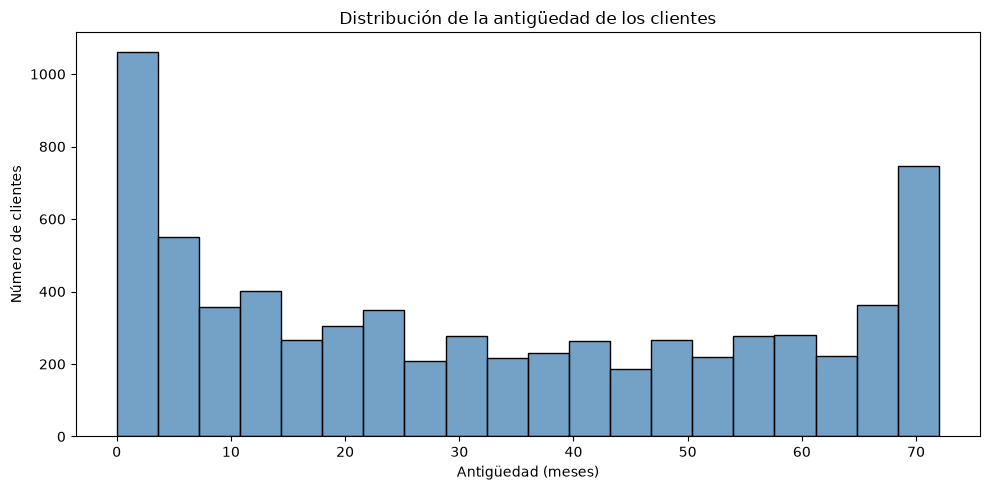

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

# Crear un histograma de la antigüedad de los clientes
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="tenure",
    bins=20,
    color="steelblue",
    edgecolor="black"
)

plt.title("Distribución de la antigüedad de los clientes")
plt.xlabel("Antigüedad (meses)")
plt.ylabel("Número de clientes")

plt.savefig(
    "../imagenes/histograma_tenure.png",
    dpi=300,
    bbox_inches="tight"
)

plt.tight_layout()
plt.show()

### 3.2. Distribución de los cargos mensuales

Se analiza la distribución de `MonthlyCharges` mediante un histograma
para identificar concentraciones de clientes según los cargos mensuales
y examinar visualmente la forma de la distribución.

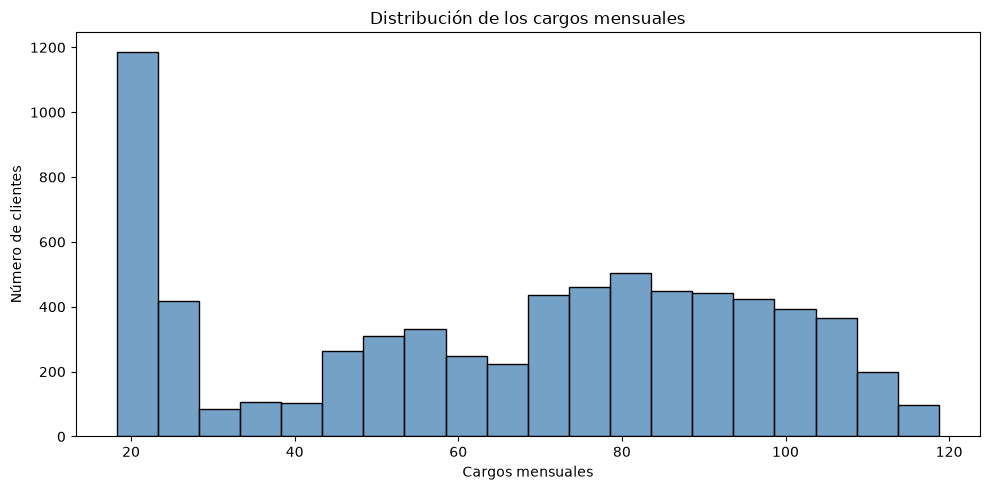

In [ ]:
# Crear un histograma de los cargos mensuales
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="MonthlyCharges",
    bins=20,
    color="steelblue",
    edgecolor="black"
)

plt.title("Distribución de los cargos mensuales")
plt.xlabel("Cargos mensuales")
plt.ylabel("Número de clientes")

plt.tight_layout()


plt.savefig(
    "../imagenes/histograma_monthlycharges.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 3.3. Análisis de valores extremos en la antigüedad

Se utiliza un diagrama de caja para examinar la dispersión,
los cuartiles y posibles valores atípicos de la variable `tenure`.

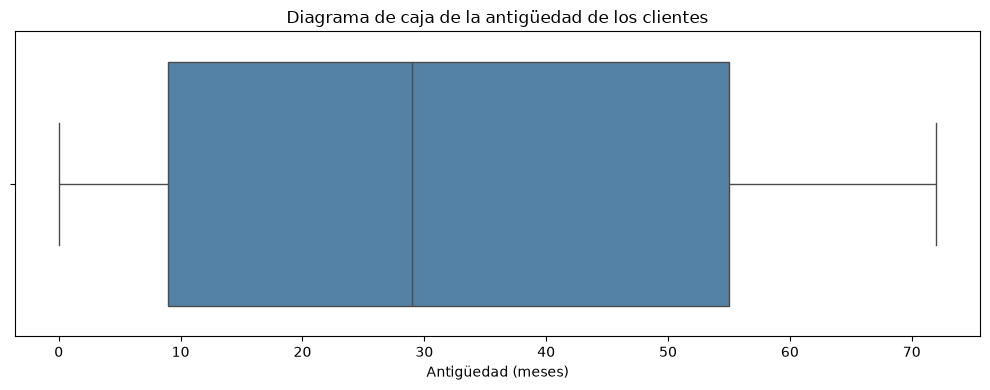

In [27]:
# Crear un diagrama de caja para la antigüedad
plt.figure(figsize=(10, 4))

sns.boxplot(
    data=df,
    x="tenure",
    color="steelblue"
)

plt.title("Diagrama de caja de la antigüedad de los clientes")
plt.xlabel("Antigüedad (meses)")

plt.tight_layout()


plt.savefig(
    "../imagenes/boxplot_tenure.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 3.4. Análisis de valores extremos en los cargos mensuales

Se utiliza un diagrama de caja para analizar la dispersión,
los cuartiles y los posibles valores atípicos de `MonthlyCharges`.

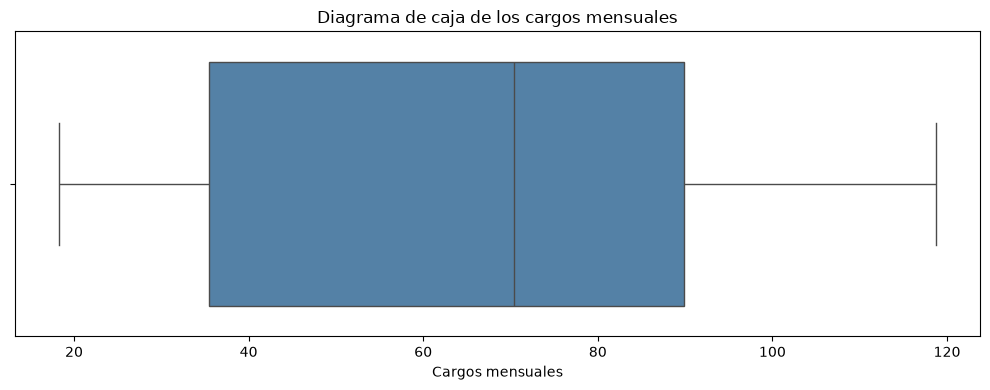

In [28]:
# Crear un diagrama de caja de los cargos mensuales
plt.figure(figsize=(10, 4))

sns.boxplot(
    data=df,
    x="MonthlyCharges",
    color="steelblue"
)

plt.title("Diagrama de caja de los cargos mensuales")
plt.xlabel("Cargos mensuales")

plt.tight_layout()


plt.savefig(
    "../imagenes/boxplot_monthlycharges.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 3.5. Distribución de la variable objetivo Churn

Se visualiza la frecuencia de las clases de la variable objetivo
para identificar el desbalance existente entre los clientes
que permanecieron y aquellos que cancelaron el servicio.

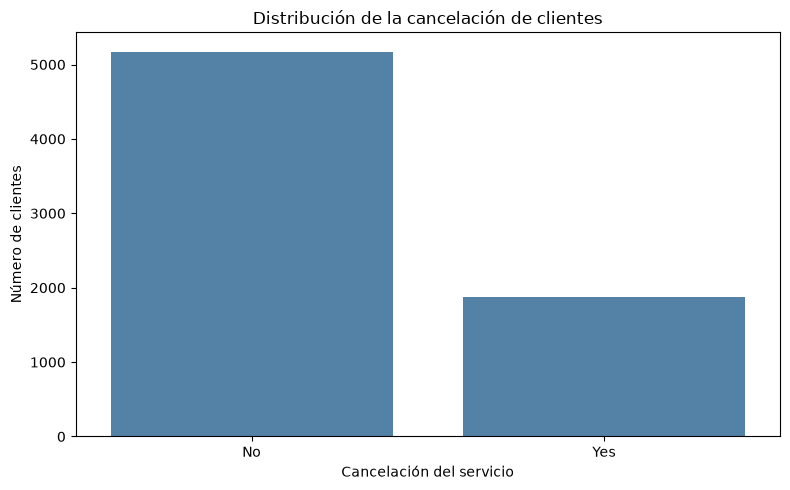

In [29]:
# Crear gráfica de barras de la variable objetivo
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Churn",
    order=["No", "Yes"],
    color="steelblue"
)

plt.title("Distribución de la cancelación de clientes")
plt.xlabel("Cancelación del servicio")
plt.ylabel("Número de clientes")

plt.tight_layout()


plt.savefig(
    "../imagenes/distribucion_churn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 3.6. Relación entre el tipo de contrato y la cancelación

Se analiza la proporción de clientes que cancelaron o
mantuvieron su servicio según el tipo de contrato.
El objetivo es identificar posibles asociaciones entre
Contract y Churn.

In [30]:
# Tabla de contingencia entre Contract y Churn
tabla_contrato_churn = pd.crosstab(
    df["Contract"],
    df["Churn"]
)

# Calcular porcentajes dentro de cada tipo de contrato
porcentaje_contrato_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print("Frecuencia absoluta por tipo de contrato:")
display(tabla_contrato_churn)

print("Porcentaje dentro de cada tipo de contrato:")
display(porcentaje_contrato_churn.round(2))

Frecuencia absoluta por tipo de contrato:


Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


Porcentaje dentro de cada tipo de contrato:


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


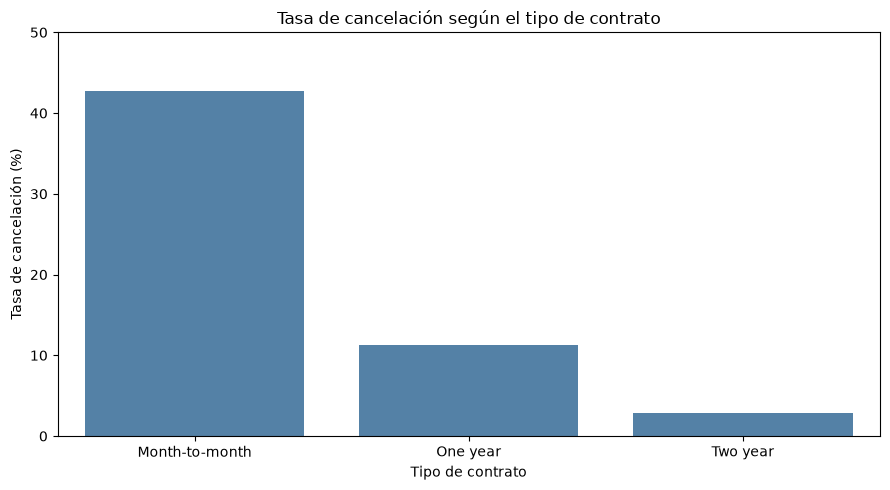

In [31]:
# Seleccionar las tasas de cancelación (Churn = Yes)
tasas_cancelacion = porcentaje_contrato_churn["Yes"]

# Crear gráfica comparativa
plt.figure(figsize=(9, 5))

sns.barplot(
    x=tasas_cancelacion.index,
    y=tasas_cancelacion.values,
    color="steelblue",
    order=["Month-to-month", "One year", "Two year"]
)

plt.title("Tasa de cancelación según el tipo de contrato")
plt.xlabel("Tipo de contrato")
plt.ylabel("Tasa de cancelación (%)")
plt.ylim(0, 50)

plt.tight_layout()


plt.savefig(
    "../imagenes/churn_por_contrato.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 3.7. Relación entre el servicio de internet y la cancelación

Se analiza la distribución de Churn según el tipo de servicio
de internet contratado, con el propósito de identificar posibles
diferencias en las tasas de cancelación.

In [32]:
# Calcular frecuencias absolutas por servicio de internet
tabla_internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"]
)

# Calcular porcentajes dentro de cada tipo de servicio
porcentaje_internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print("Frecuencia absoluta por servicio de internet:")
display(tabla_internet_churn)

print("Porcentaje dentro de cada tipo de servicio:")
display(porcentaje_internet_churn.round(2))

Frecuencia absoluta por servicio de internet:


Churn,No,Yes
InternetService,,
DSL,1962,459
Fiber optic,1799,1297
No,1413,113


Porcentaje dentro de cada tipo de servicio:


Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


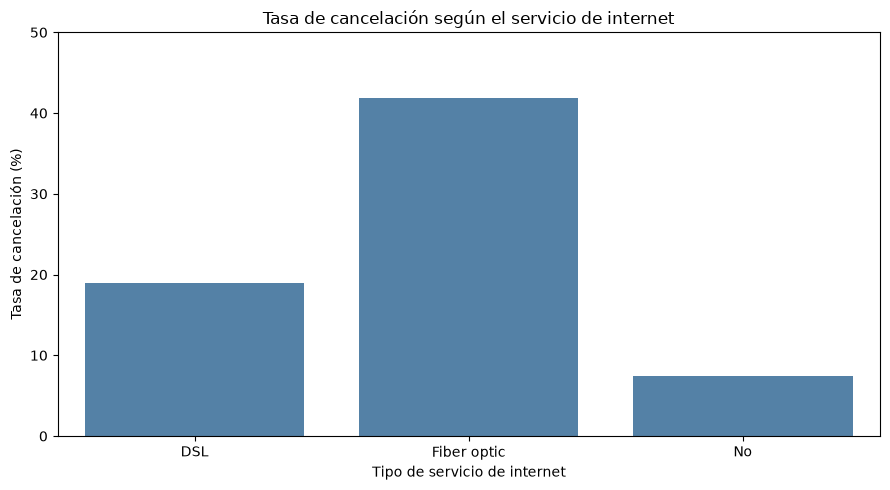

In [33]:
# Seleccionar los porcentajes de clientes que cancelaron
tasas_internet = porcentaje_internet_churn["Yes"]

# Crear la gráfica
plt.figure(figsize=(9, 5))

sns.barplot(
    x=tasas_internet.index,
    y=tasas_internet.values,
    order=["DSL", "Fiber optic", "No"],
    color="steelblue"
)

plt.title("Tasa de cancelación según el servicio de internet")
plt.xlabel("Tipo de servicio de internet")
plt.ylabel("Tasa de cancelación (%)")
plt.ylim(0, 50)

plt.tight_layout()


plt.savefig(
    "../imagenes/churn_por_internet.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 3.8. Relación entre la antigüedad y la cancelación

Se compara la distribución de la antigüedad de los clientes
según la variable objetivo Churn, utilizando diagramas de caja
para identificar diferencias en las medianas, la dispersión
y posibles valores atípicos.

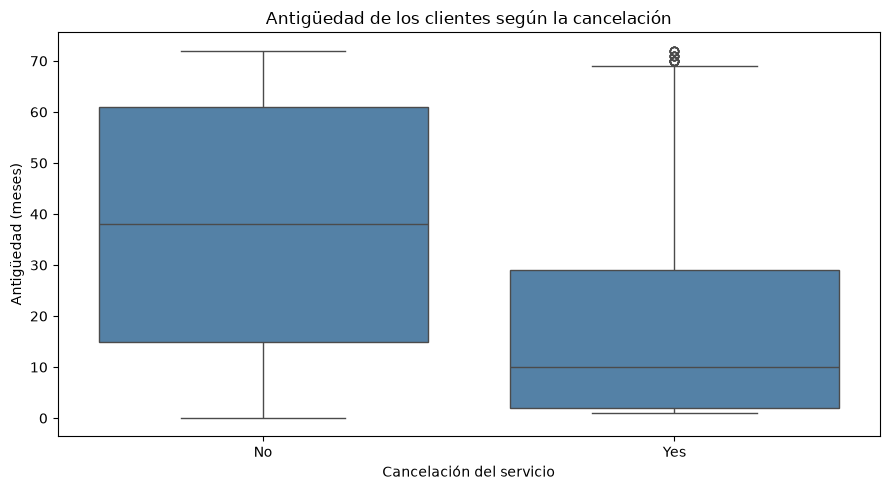

In [34]:
# Comparar la antigüedad según la cancelación del servicio
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure",
    order=["No", "Yes"],
    color="steelblue"
)

plt.title("Antigüedad de los clientes según la cancelación")
plt.xlabel("Cancelación del servicio")
plt.ylabel("Antigüedad (meses)")

plt.tight_layout()


plt.savefig(
    "../imagenes/tenure_por_churn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 3.9. Relación entre los cargos mensuales y la cancelación

Se compara la distribución de MonthlyCharges según la variable
objetivo Churn, utilizando diagramas de caja para identificar
diferencias en las medianas, la dispersión y posibles valores atípicos.

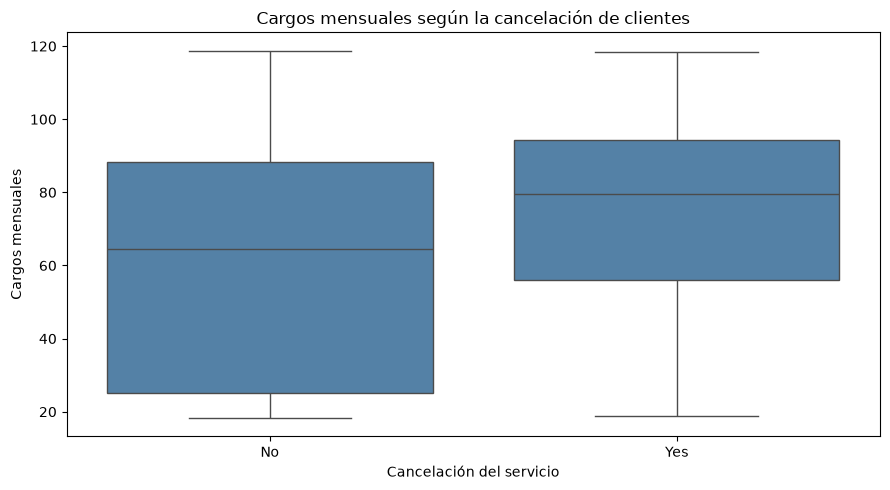

In [35]:
# Comparar los cargos mensuales según la cancelación
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges",
    order=["No", "Yes"],
    color="steelblue"
)

plt.title("Cargos mensuales según la cancelación de clientes")
plt.xlabel("Cancelación del servicio")
plt.ylabel("Cargos mensuales")

plt.tight_layout()


plt.savefig(
    "../imagenes/monthlycharges_por_churn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 4. Comparación de estrategias de imputación

### 4.1. Preparación de la variable TotalCharges

Se prepara una copia del dataset para convertir la variable
TotalCharges a un tipo numérico e identificar los valores ausentes.



In [3]:
# Crear una copia del DataFrame original
df_preparacion = df.copy()

# Convertir TotalCharges a valores numéricos
df_preparacion["TotalCharges"] = pd.to_numeric(
    df_preparacion["TotalCharges"],
    errors="coerce"
)

# Comprobar el nuevo tipo de dato
print("Tipo de dato de TotalCharges:")
print(df_preparacion["TotalCharges"].dtype)

# Contar valores ausentes después de la conversión
print("\nValores ausentes en TotalCharges:")
print(df_preparacion["TotalCharges"].isna().sum())

# Verificar las dimensiones del dataset
print("\nDimensiones del dataset:")
print(df_preparacion.shape)

Tipo de dato de TotalCharges:
float64

Valores ausentes en TotalCharges:
11

Dimensiones del dataset:
(7043, 21)


### 4.2. Separación de entrenamiento y prueba

Se divide el dataset en conjuntos de entrenamiento (80%) y prueba
(20%), utilizando una separación estratificada según la variable Churn.

Esta división permite evaluar posteriormente diferentes estrategias
de preprocesamiento y clasificación, evitando ajustar las
transformaciones con información del conjunto de prueba.

In [4]:
from sklearn.model_selection import train_test_split

# Separar las variables predictoras de la variable objetivo
X = df_preparacion.drop(columns=["Churn", "customerID"])
y = df_preparacion["Churn"]

# Dividir los datos en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Mostrar las dimensiones resultantes
print("Dimensiones de X_train:", X_train.shape)
print("Dimensiones de X_test:", X_test.shape)

print("\nDistribución de Churn en entrenamiento (%):")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nDistribución de Churn en prueba (%):")
print(y_test.value_counts(normalize=True).mul(100).round(2))

Dimensiones de X_train: (5634, 19)
Dimensiones de X_test: (1409, 19)

Distribución de Churn en entrenamiento (%):
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

Distribución de Churn en prueba (%):
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


### 4.3. Distribución de valores ausentes

Se verifica la cantidad de valores ausentes de TotalCharges
en los conjuntos de entrenamiento y prueba antes de aplicar
las estrategias de imputación.

In [5]:
# Contar los valores ausentes en entrenamiento
nulos_train = X_train["TotalCharges"].isna().sum()

# Contar los valores ausentes en prueba
nulos_test = X_test["TotalCharges"].isna().sum()

# Mostrar los resultados
print("Valores ausentes en entrenamiento:", nulos_train)
print("Valores ausentes en prueba:", nulos_test)

print("\nTotal de valores ausentes:", nulos_train + nulos_test)

Valores ausentes en entrenamiento: 8
Valores ausentes en prueba: 3

Total de valores ausentes: 11


### 4.4. Comparación de estrategias de imputación

Se calculan la media y la mediana de TotalCharges utilizando
exclusivamente el conjunto de entrenamiento.

Estos valores permitirán estudiar diferentes estrategias de
imputación sin utilizar información del conjunto de prueba.

In [6]:
# Calcular la media de TotalCharges en entrenamiento
media_totalcharges = X_train["TotalCharges"].mean()

# Calcular la mediana de TotalCharges en entrenamiento
mediana_totalcharges = X_train["TotalCharges"].median()

# Mostrar los resultados
print("Media de TotalCharges:", round(media_totalcharges, 2))
print("Mediana de TotalCharges:", round(mediana_totalcharges, 2))

Media de TotalCharges: 2302.6
Mediana de TotalCharges: 1398.12


### 4.5. Relación entre antigüedad y cargos totales

Se examina la relación entre tenure y TotalCharges
utilizando exclusivamente los datos de entrenamiento,
con el propósito de identificar posibles dependencias
relevantes para la selección de estrategias de imputación.

In [7]:
# Calcular la correlación entre antigüedad y cargos totales
correlacion_totalcharges = X_train[
    ["tenure", "TotalCharges"]
].corr(method="pearson")

print("Correlación entre tenure y TotalCharges:")
display(correlacion_totalcharges)

Correlación entre tenure y TotalCharges:


,tenure,TotalCharges
tenure,1.000000,0.829433
TotalCharges,0.829433,1.000000


### 4.6. Estrategias de imputación propuestas

Se consideran tres estrategias para tratar los valores ausentes
de TotalCharges:

1. Imputación utilizando la media del conjunto de entrenamiento.
2. Imputación utilizando la mediana del conjunto de entrenamiento.
3. Imputación basada en una regla de dominio para clientes con
   tenure igual a cero.

Las estrategias se evaluarán sin utilizar el conjunto de prueba
para seleccionar el método de imputación.

In [8]:
from sklearn.impute import SimpleImputer

# Crear copias para la estrategia de imputación por media
X_train_media = X_train.copy()
X_test_media = X_test.copy()

# Definir el imputador por media
imputador_media = SimpleImputer(strategy="mean")

# Aprender la media utilizando únicamente entrenamiento
X_train_media[["TotalCharges"]] = imputador_media.fit_transform(
    X_train[["TotalCharges"]]
)

# Aplicar la misma media al conjunto de prueba
X_test_media[["TotalCharges"]] = imputador_media.transform(
    X_test[["TotalCharges"]]
)

# Verificar los valores ausentes después de imputar
print("Valores ausentes en entrenamiento:",
      X_train_media["TotalCharges"].isna().sum())

print("Valores ausentes en prueba:",
      X_test_media["TotalCharges"].isna().sum())

# Mostrar la media aprendida
print("Media utilizada para imputar:",
      round(imputador_media.statistics_[0], 2))

Valores ausentes en entrenamiento: 0
Valores ausentes en prueba: 0
Media utilizada para imputar: 2302.6


In [9]:
from sklearn.impute import SimpleImputer

# Crear copias para la estrategia de imputación por mediana
X_train_mediana = X_train.copy()
X_test_mediana = X_test.copy()

# Definir el imputador por mediana
imputador_mediana = SimpleImputer(strategy="median")

# Aprender la mediana únicamente con entrenamiento
X_train_mediana[["TotalCharges"]] = imputador_mediana.fit_transform(
    X_train[["TotalCharges"]]
)

# Aplicar la mediana aprendida al conjunto de prueba
X_test_mediana[["TotalCharges"]] = imputador_mediana.transform(
    X_test[["TotalCharges"]]
)

# Verificar los valores ausentes
print("Valores ausentes en entrenamiento:",
      X_train_mediana["TotalCharges"].isna().sum())

print("Valores ausentes en prueba:",
      X_test_mediana["TotalCharges"].isna().sum())

# Mostrar la mediana aprendida
print("Mediana utilizada para imputar:",
      round(imputador_mediana.statistics_[0], 2))

Valores ausentes en entrenamiento: 0
Valores ausentes en prueba: 0
Mediana utilizada para imputar: 1398.12


In [10]:
# Crear copias independientes de los conjuntos originales
X_train_dominio = X_train.copy()
X_test_dominio = X_test.copy()

# Identificar registros con TotalCharges ausente y tenure igual a cero
mascara_train = (
    X_train_dominio["TotalCharges"].isna()
    & (X_train_dominio["tenure"] == 0)
)

mascara_test = (
    X_test_dominio["TotalCharges"].isna()
    & (X_test_dominio["tenure"] == 0)
)

# Aplicar la regla de dominio
X_train_dominio.loc[mascara_train, "TotalCharges"] = 0
X_test_dominio.loc[mascara_test, "TotalCharges"] = 0

# Mostrar los resultados
print("Registros imputados en entrenamiento:", mascara_train.sum())
print("Registros imputados en prueba:", mascara_test.sum())

print("\nValores ausentes restantes en entrenamiento:",
      X_train_dominio["TotalCharges"].isna().sum())

print("Valores ausentes restantes en prueba:",
      X_test_dominio["TotalCharges"].isna().sum())

Registros imputados en entrenamiento: 8
Registros imputados en prueba: 3

Valores ausentes restantes en entrenamiento: 0
Valores ausentes restantes en prueba: 0


### 4.7. Comparación de los valores imputados

Se comparan los resultados de las tres estrategias de imputación:
media, mediana y regla de dominio.

El objetivo es examinar los valores asignados a los registros
originalmente incompletos, sin modificar los conjuntos originales.

In [11]:
# Identificar los registros originalmente incompletos en entrenamiento
indices_ausentes = X_train["TotalCharges"].isna()

# Construir una tabla para comparar las imputaciones
comparacion_imputacion = pd.DataFrame({
    "tenure": X_train.loc[indices_ausentes, "tenure"],
    "MonthlyCharges": X_train.loc[indices_ausentes, "MonthlyCharges"],
    "Media": X_train_media.loc[indices_ausentes, "TotalCharges"],
    "Mediana": X_train_mediana.loc[indices_ausentes, "TotalCharges"],
    "Regla de dominio": X_train_dominio.loc[indices_ausentes, "TotalCharges"]
})

# Mostrar únicamente los registros afectados
display(comparacion_imputacion.round(2))

,tenure,MonthlyCharges,Media,Mediana,Regla de dominio
6670,0,73.35,2302.6,1398.12,0.0
4380,0,20.00,2302.6,1398.12,0.0
3826,0,25.35,2302.6,1398.12,0.0
488,0,52.55,2302.6,1398.12,0.0
1082,0,25.75,2302.6,1398.12,0.0
1340,0,56.05,2302.6,1398.12,0.0
6754,0,61.90,2302.6,1398.12,0.0
3331,0,19.85,2302.6,1398.12,0.0


In [12]:
# Verificar que los conjuntos originales conservan sus valores ausentes
print("Valores ausentes originales en entrenamiento:")
print(X_train["TotalCharges"].isna().sum())

print("\nValores ausentes originales en prueba:")
print(X_test["TotalCharges"].isna().sum())

# Verificar que las dimensiones no cambiaron
print("\nDimensiones originales:")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

# Comprobar que las tres estrategias conservaron las dimensiones
print("\nDimensiones después de imputar:")
print("Media:", X_train_media.shape)
print("Mediana:", X_train_mediana.shape)
print("Regla de dominio:", X_train_dominio.shape)

Valores ausentes originales en entrenamiento:
8

Valores ausentes originales en prueba:
3

Dimensiones originales:
X_train: (5634, 19)
X_test: (1409, 19)

Dimensiones después de imputar:
Media: (5634, 19)
Mediana: (5634, 19)
Regla de dominio: (5634, 19)


### 4.8. Diseño de la evaluación comparativa

Se compararán las estrategias de imputación por media, mediana
y regla de dominio mediante validación cruzada estratificada
de cinco particiones.

Se utilizará el mismo clasificador y las mismas particiones
para garantizar condiciones comparables.

El preprocesamiento se ajustará dentro de cada partición
de entrenamiento para evitar fugas de información.

Las métricas principales serán precision, recall, F1-score
y PR-AUC, considerando Churn = Yes como clase positiva.


In [13]:
from sklearn.model_selection import StratifiedKFold

# Configurar la validación cruzada estratificada
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Mostrar la configuración
print("Número de particiones:", cv.get_n_splits())

print("Registros de entrenamiento disponibles:", len(X_train))

print("\nDistribución de la variable objetivo:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

Número de particiones: 5
Registros de entrenamiento disponibles: 5634

Distribución de la variable objetivo:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [14]:
# Identificar variables numéricas continuas
columnas_numericas = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

# Identificar variables categóricas
columnas_categoricas = [
    columna for columna in X_train.columns
    if columna not in columnas_numericas
]

# Mostrar las columnas identificadas
print("Variables numéricas:")
print(columnas_numericas)

print("\nVariables categóricas:")
print(columnas_categoricas)

print("\nTotal de variables numéricas:", len(columnas_numericas))
print("Total de variables categóricas:", len(columnas_categoricas))
print("Total de variables:", len(columnas_numericas) + len(columnas_categoricas))

Variables numéricas:
['tenure', 'MonthlyCharges', 'TotalCharges']

Variables categóricas:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Total de variables numéricas: 3
Total de variables categóricas: 16
Total de variables: 19


In [16]:
from sklearn.preprocessing import OneHotEncoder

# Configurar el codificador para variables categóricas
codificador_categorico = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)


print("Codificador categórico configurado:")
print(codificador_categorico)

Codificador categórico configurado:
OneHotEncoder(handle_unknown='ignore', sparse_output=False)


In [17]:
from sklearn.compose import ColumnTransformer

# Definir los grupos de columnas
columnas_numericas_sin_nulos = [
    "tenure",
    "MonthlyCharges"
]

columna_imputacion = ["TotalCharges"]

# Configurar el preprocesamiento para imputación por media
preprocesador_media = ColumnTransformer(
    transformers=[
        ("numericas", "passthrough", columnas_numericas_sin_nulos),
        ("totalcharges", SimpleImputer(strategy="mean"), columna_imputacion),
        ("categoricas", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), columnas_categoricas)
    ]
)

print("Preprocesador por media configurado:")
print(preprocesador_media)

Preprocesador por media configurado:
ColumnTransformer(transformers=[('numericas', 'passthrough',
                                 ['tenure', 'MonthlyCharges']),
                                ('totalcharges', SimpleImputer(),
                                 ['TotalCharges']),
                                ('categoricas',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['gender', 'SeniorCitizen', 'Partner',
                                  'Dependents', 'PhoneService', 'MultipleLines',
                                  'InternetService', 'OnlineSecurity',
                                  'OnlineBackup', 'DeviceProtection',
                                  'TechSupport', 'StreamingTV',
                                  'StreamingMovies', 'Contract',
                                  'PaperlessBilling', 'PaymentMethod'])])


In [18]:
# Configurar el preprocesamiento para imputación por mediana
preprocesador_mediana = ColumnTransformer(
    transformers=[
        ("numericas", "passthrough", columnas_numericas_sin_nulos),
        ("totalcharges", SimpleImputer(strategy="median"), columna_imputacion),
        ("categoricas", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), columnas_categoricas)
    ]
)

print("Preprocesador por mediana configurado:")
print(preprocesador_mediana)

Preprocesador por mediana configurado:
ColumnTransformer(transformers=[('numericas', 'passthrough',
                                 ['tenure', 'MonthlyCharges']),
                                ('totalcharges',
                                 SimpleImputer(strategy='median'),
                                 ['TotalCharges']),
                                ('categoricas',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['gender', 'SeniorCitizen', 'Partner',
                                  'Dependents', 'PhoneService', 'MultipleLines',
                                  'InternetService', 'OnlineSecurity',
                                  'OnlineBackup', 'DeviceProtection',
                                  'TechSupport', 'StreamingTV',
                                  'StreamingMovies', 'Contract',
                                  'PaperlessBilling', 'P

In [19]:
from sklearn.preprocessing import FunctionTransformer

# Definir la función para la regla de dominio
def imputar_por_dominio(datos):
    datos = datos.copy()

    mascara = (
        datos["TotalCharges"].isna()
        & (datos["tenure"] == 0)
    )

    datos.loc[mascara, "TotalCharges"] = 0

    return datos[["TotalCharges"]]


# Crear el transformador personalizado
transformador_dominio = FunctionTransformer(
    imputar_por_dominio,
    validate=False
)

print("Transformador de dominio configurado:")
print(transformador_dominio)

Transformador de dominio configurado:
FunctionTransformer(func=<function imputar_por_dominio at 0x000001D97D4A0CA0>)


In [20]:
# Configurar el preprocesamiento para la regla de dominio
preprocesador_dominio = ColumnTransformer(
    transformers=[
        ("numericas", "passthrough", ["tenure", "MonthlyCharges"]),

        ("totalcharges", transformador_dominio, ["tenure", "TotalCharges"]),

        ("categoricas", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), columnas_categoricas)
    ]
)

print("Preprocesador por regla de dominio configurado:")
print(preprocesador_dominio)

Preprocesador por regla de dominio configurado:
ColumnTransformer(transformers=[('numericas', 'passthrough',
                                 ['tenure', 'MonthlyCharges']),
                                ('totalcharges',
                                 FunctionTransformer(func=<function imputar_por_dominio at 0x000001D97D4A0CA0>),
                                 ['tenure', 'TotalCharges']),
                                ('categoricas',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['gender', 'SeniorCitizen', 'Partner',
                                  'Dependents', 'PhoneService', 'MultipleLines',
                                  'InternetService', 'OnlineSecurity',
                                  'OnlineBackup', 'DeviceProtection',
                                  'TechSupport', 'StreamingTV',
                                  'StreamingMovies', 'Co

### 4.9. Configuración del clasificador

Se utiliza un modelo de regresión logística como clasificador
de referencia para comparar el impacto de las estrategias
de imputación sobre el desempeño predictivo.

Se mantiene la misma configuración del clasificador para
las tres estrategias, utilizando validación cruzada
estratificada sobre el conjunto de entrenamiento.

In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# Configurar el clasificador de referencia
clasificador = LogisticRegression(
    max_iter=2000,
    solver="lbfgs",
    random_state=42
)

print("Clasificador configurado:")
print(clasificador)

Clasificador configurado:
LogisticRegression(max_iter=2000, random_state=42)


In [22]:
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Crear un pipeline con el preprocesador por media
# y la estandarización de las variables resultantes
pipeline_media = Pipeline(
    steps=[
        ("preprocesamiento", clone(preprocesador_media)),
        ("escalado", StandardScaler()),
        ("clasificador", clone(clasificador))
    ]
)

print("Pipeline por media configurado:")
print(pipeline_media)

Pipeline por media configurado:
Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('numericas', 'passthrough',
                                                  ['tenure', 'MonthlyCharges']),
                                                 ('totalcharges',
                                                  SimpleImputer(),
                                                  ['TotalCharges']),
                                                 ('categoricas',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['gender', 'SeniorCitizen',
                                                   'Partner', 'Dependents',
                                                   'PhoneService',
                                                   'MultipleLines',
                                         

In [23]:
# Pipeline para imputación por mediana
pipeline_mediana = Pipeline(
    steps=[
        ("preprocesamiento", clone(preprocesador_mediana)),
        ("escalado", StandardScaler()),
        ("clasificador", clone(clasificador))
    ]
)

# Pipeline para imputación por regla de dominio
pipeline_dominio = Pipeline(
    steps=[
        ("preprocesamiento", clone(preprocesador_dominio)),
        ("escalado", StandardScaler()),
        ("clasificador", clone(clasificador))
    ]
)

print("Pipeline por mediana configurado:")
print([nombre for nombre, paso in pipeline_mediana.steps])

print("\nPipeline por regla de dominio configurado:")
print([nombre for nombre, paso in pipeline_dominio.steps])

Pipeline por mediana configurado:
['preprocesamiento', 'escalado', 'clasificador']

Pipeline por regla de dominio configurado:
['preprocesamiento', 'escalado', 'clasificador']


### 4.10. Métricas de evaluación

Se utilizarán accuracy, precision, recall, F1-score y
Average Precision (AP) para comparar las estrategias
de imputación mediante validación cruzada estratificada.

Se considera Churn = Yes como clase positiva.

La comparación se realizará exclusivamente con los datos
de entrenamiento, manteniendo reservado el conjunto de prueba.

In [ ]:
from sklearn.metrics import (
    make_scorer,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

# Configurar las métricas de evaluación
metricas = {
    "accuracy": "accuracy",

    "precision": make_scorer(
        precision_score,
        pos_label="Yes",
        zero_division=0
    ),

    "recall": make_scorer(
        recall_score,
        pos_label="Yes",
        zero_division=0
    ),

    "f1": make_scorer(
        f1_score,
        pos_label="Yes",
        zero_division=0
    ),

    "average_precision": make_scorer(
        average_precision_score,
        response_method="predict_proba",
        pos_label="Yes"
    )
}

print("Métricas configuradas para la validación cruzada:")

for nombre in metricas:
    print("-", nombre)

Métricas configuradas para la validación cruzada:
- accuracy
- precision
- recall
- f1
- average_precision


In [25]:
from sklearn.model_selection import cross_validate

# Evaluar únicamente el pipeline de imputación por media
resultados_media = cross_validate(
    estimator=pipeline_media,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=metricas,
    n_jobs=1,
    error_score="raise"
)

print("Resultados de validación cruzada - Imputación por media")

for nombre in metricas:
    valores = resultados_media[f"test_{nombre}"]
    print(f"{nombre}: {valores.mean():.4f} (+/- {valores.std():.4f})")

Resultados de validación cruzada - Imputación por media
accuracy: 0.8025 (+/- 0.0120)
precision: 0.6531 (+/- 0.0253)
recall: 0.5452 (+/- 0.0435)
f1: 0.5936 (+/- 0.0313)
average_precision: 0.6612 (+/- 0.0193)


In [26]:
# Evaluar el pipeline de imputación por mediana
resultados_mediana = cross_validate(
    estimator=pipeline_mediana,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=metricas,
    n_jobs=1,
    error_score="raise"
)

print("Resultados de validación cruzada - Imputación por mediana")

for nombre in metricas:
    valores = resultados_mediana[f"test_{nombre}"]
    print(f"{nombre}: {valores.mean():.4f} (+/- {valores.std():.4f})")

Resultados de validación cruzada - Imputación por mediana
accuracy: 0.8025 (+/- 0.0119)
precision: 0.6531 (+/- 0.0255)
recall: 0.5452 (+/- 0.0420)
f1: 0.5936 (+/- 0.0306)
average_precision: 0.6611 (+/- 0.0192)


In [27]:
# Evaluar el pipeline de imputación por regla de dominio
resultados_dominio = cross_validate(
    estimator=pipeline_dominio,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=metricas,
    n_jobs=1,
    error_score="raise"
)

print("Resultados de validación cruzada - Regla de dominio")

for nombre in metricas:
    valores = resultados_dominio[f"test_{nombre}"]
    print(f"{nombre}: {valores.mean():.4f} (+/- {valores.std():.4f})")

Resultados de validación cruzada - Regla de dominio
accuracy: 0.8023 (+/- 0.0118)
precision: 0.6525 (+/- 0.0247)
recall: 0.5452 (+/- 0.0420)
f1: 0.5934 (+/- 0.0305)
average_precision: 0.6613 (+/- 0.0191)


### 4.11. Comparación de resultados de imputación

Se presentan los resultados promedio de validación cruzada
de las tres estrategias de imputación evaluadas.

La comparación considera accuracy, precision, recall,
F1-score y Average Precision.

Las diferencias se interpretan considerando tanto el
desempeño predictivo como la coherencia de los valores
imputados con el dominio del problema.

In [28]:
# Organizar los resultados de las tres estrategias
resultados_imputacion = {
    "Media": resultados_media,
    "Mediana": resultados_mediana,
    "Regla de dominio": resultados_dominio
}

# Crear tabla comparativa
tabla_imputacion = pd.DataFrame({
    estrategia: {
        metrica: resultados[f"test_{metrica}"].mean()
        for metrica in metricas
    }
    for estrategia, resultados in resultados_imputacion.items()
}).T

print("Comparación de estrategias de imputación:")
display(tabla_imputacion.round(4))

Comparación de estrategias de imputación:


,accuracy,precision,recall,f1,average_precision
Media,0.8025,0.6531,0.5452,0.5936,0.6612
Mediana,0.8025,0.6531,0.5452,0.5936,0.6611
Regla de dominio,0.8023,0.6525,0.5452,0.5934,0.6613


### 4.12. Impacto de la imputación sobre la distribución y la varianza

Se comparan las estadísticas descriptivas de TotalCharges antes
y después de aplicar las tres estrategias de imputación.

El análisis se realiza sobre los datos de entrenamiento para
identificar cambios en la tendencia central y la dispersión


In [29]:
# Reunir las cuatro versiones de TotalCharges
versiones_totalcharges = pd.DataFrame({
    "Original": X_train["TotalCharges"],
    "Media": X_train_media["TotalCharges"],
    "Mediana": X_train_mediana["TotalCharges"],
    "Regla de dominio": X_train_dominio["TotalCharges"]
})

# Calcular estadísticas descriptivas de cada versión
comparacion_estadisticas = pd.DataFrame({
    "Media": versiones_totalcharges.mean(),
    "Mediana": versiones_totalcharges.median(),
    "Varianza": versiones_totalcharges.var(),
    "Desviación estándar": versiones_totalcharges.std(),
    "Valores ausentes": versiones_totalcharges.isna().sum()
})

print("Estadísticas antes y después de la imputación:")
display(comparacion_estadisticas.round(2))

Estadísticas antes y después de la imputación:


,Media,Mediana,Varianza,Desviación estándar,Valores ausentes
Original,2302.60,1398.12,5194630.36,2279.17,8
Media,2302.60,1401.82,5187252.94,2277.55,0
Mediana,2301.32,1398.12,5188413.13,2277.81,0
Regla de dominio,2299.33,1394.92,5194772.14,2279.20,0


### 4.13. Identificación de concentraciones artificiales

Se examina si las estrategias de imputación generan acumulaciones
de observaciones en valores específicos de TotalCharges.

El análisis permite identificar posibles modificaciones artificiales
en la frecuencia de los valores imputados.

In [30]:
# Contar la frecuencia del valor utilizado por cada estrategia

valores_imputados = {
    "Media": imputador_media.statistics_[0],
    "Mediana": imputador_mediana.statistics_[0],
    "Regla de dominio": 0.0
}

versiones_imputadas = {
    "Media": X_train_media["TotalCharges"],
    "Mediana": X_train_mediana["TotalCharges"],
    "Regla de dominio": X_train_dominio["TotalCharges"]
}

# Comparar la frecuencia antes y después
for estrategia, valor in valores_imputados.items():

    frecuencia_original = X_train["TotalCharges"].eq(valor).sum()
    frecuencia_final = versiones_imputadas[estrategia].eq(valor).sum()

    print(f"\nEstrategia: {estrategia}")
    print(f"Frecuencia original: {frecuencia_original}")
    print(f"Frecuencia después de imputar: {frecuencia_final}")
    print(f"Incremento artificial: {frecuencia_final - frecuencia_original}")


Estrategia: Media
Frecuencia original: 0
Frecuencia después de imputar: 8
Incremento artificial: 8

Estrategia: Mediana
Frecuencia original: 0
Frecuencia después de imputar: 8
Incremento artificial: 8

Estrategia: Regla de dominio
Frecuencia original: 0
Frecuencia después de imputar: 8
Incremento artificial: 8


### 4.14. Experimento de imputación categórica

Se selecciona la variable Contract para comparar dos estrategias
de imputación categórica: moda y categoría Desconocido.

Dado que esta variable no contiene valores ausentes originales,
se realizará una simulación controlada de ausencia de datos
exclusivamente sobre el conjunto de entrenamiento.

Los valores ausentes simulados se distinguirán de los originales
y se utilizará una semilla fija para garantizar la reproducibilidad.

In [31]:
import numpy as np

# Crear una copia del conjunto de entrenamiento
X_train_categorico = X_train.copy()

# Configurar un generador de números aleatorios reproducible
rng = np.random.default_rng(42)

# Definir el porcentaje de ausencias simuladas
porcentaje_ausencia = 0.05

# Calcular cuántos registros se modificarán
cantidad_ausencias = round(
    len(X_train_categorico) * porcentaje_ausencia
)

# Seleccionar posiciones aleatorias sin repetición
posiciones_ausentes = rng.choice(
    len(X_train_categorico),
    size=cantidad_ausencias,
    replace=False
)

# Identificar los índices correspondientes
indices_simulados = X_train_categorico.index[posiciones_ausentes]

# Simular los valores ausentes únicamente en Contract
X_train_categorico.loc[indices_simulados, "Contract"] = np.nan

print("Registros de entrenamiento:", len(X_train_categorico))

print("Ausencias simuladas en Contract:",
      X_train_categorico["Contract"].isna().sum())

print("Porcentaje de ausencias simulado:",
      round(X_train_categorico["Contract"].isna().mean() * 100, 2), "%")

print("Ausencias en Contract del conjunto original:",
      X_train["Contract"].isna().sum())

print("Ausencias en Contract del conjunto de prueba:",
      X_test["Contract"].isna().sum())

Registros de entrenamiento: 5634
Ausencias simuladas en Contract: 282
Porcentaje de ausencias simulado: 5.01 %
Ausencias en Contract del conjunto original: 0
Ausencias en Contract del conjunto de prueba: 0


### 4.15. Imputación categórica por moda

Se aplica la imputación por moda sobre la variable Contract,
utilizando los valores disponibles del conjunto de entrenamiento.

El objetivo es analizar cómo esta estrategia modifica las
frecuencias de las categorías después de sustituir las
ausencias simuladas.

In [32]:
# Crear una copia de los datos con ausencias simuladas
X_train_moda = X_train_categorico.copy()

# Definir el imputador categórico por moda
imputador_moda = SimpleImputer(strategy="most_frequent")

# Ajustar el imputador utilizando entrenamiento
X_train_moda[["Contract"]] = imputador_moda.fit_transform(
    X_train_categorico[["Contract"]]
)

# Mostrar la categoría utilizada
print("Moda utilizada para imputar:")
print(imputador_moda.statistics_[0])

# Comprobar valores ausentes después de imputar
print("\nValores ausentes restantes:")
print(X_train_moda["Contract"].isna().sum())

# Mostrar las frecuencias resultantes
print("\nFrecuencias de Contract después de imputar:")
print(X_train_moda["Contract"].value_counts())

Moda utilizada para imputar:
Month-to-month

Valores ausentes restantes:
0

Frecuencias de Contract después de imputar:
Contract
Month-to-month    3228
Two year          1294
One year          1112
Name: count, dtype: int64


### 4.16. Imputación categórica mediante categoría Desconocido

Se aplica una estrategia de imputación constante sobre la
variable Contract, sustituyendo los valores ausentes simulados
por una categoría denominada Desconocido.

El objetivo es comparar este tratamiento con la imputación
por moda y estudiar los cambios en las frecuencias categóricas.

In [33]:
# Crear una copia de los datos con ausencias simuladas
X_train_desconocido = X_train_categorico.copy()

# Configurar la imputación mediante una categoría constante
imputador_desconocido = SimpleImputer(
    strategy="constant",
    fill_value="Desconocido"
)

# Aplicar la imputación
X_train_desconocido[["Contract"]] = imputador_desconocido.fit_transform(
    X_train_categorico[["Contract"]]
)

# Mostrar la categoría utilizada
print("Categoría utilizada para imputar:")
print(imputador_desconocido.fill_value)

# Verificar valores ausentes
print("\nValores ausentes restantes:")
print(X_train_desconocido["Contract"].isna().sum())

# Mostrar frecuencias resultantes
print("\nFrecuencias de Contract después de imputar:")
print(X_train_desconocido["Contract"].value_counts())

Categoría utilizada para imputar:
Desconocido

Valores ausentes restantes:
0

Frecuencias de Contract después de imputar:
Contract
Month-to-month    2946
Two year          1294
One year          1112
Desconocido        282
Name: count, dtype: int64


In [34]:
# Recuperar los contratos originales de los registros ocultados
contratos_originales = X_train.loc[indices_simulados, "Contract"]

# Recuperar los valores asignados por cada estrategia
contratos_moda = X_train_moda.loc[indices_simulados, "Contract"]
contratos_desconocido = X_train_desconocido.loc[
    indices_simulados, "Contract"
]

# Comparar la imputación por moda con los valores originales
aciertos_moda = (contratos_originales == contratos_moda).sum()

# Calcular el porcentaje de aciertos
porcentaje_aciertos = aciertos_moda / len(indices_simulados) * 100

print("Registros con ausencia simulada:", len(indices_simulados))
print("Contratos recuperados correctamente por moda:", aciertos_moda)
print("Porcentaje de aciertos de la moda:", round(porcentaje_aciertos, 2))

print("\nDistribución real de los contratos ocultados:")
print(contratos_originales.value_counts())

print("\nRegistros asignados a Desconocido:")
print((contratos_desconocido == "Desconocido").sum())

Registros con ausencia simulada: 282
Contratos recuperados correctamente por moda: 156
Porcentaje de aciertos de la moda: 55.32

Distribución real de los contratos ocultados:
Contract
Month-to-month    156
Two year           65
One year           61
Name: count, dtype: int64

Registros asignados a Desconocido:
282


### 4.17. Evaluación predictiva de las estrategias categóricas

Se compara el impacto de la imputación por moda y por categoría
Desconocido sobre el desempeño del clasificador.

Se utiliza la misma validación cruzada estratificada de cinco
particiones y el mismo modelo de regresión logística.

Los imputadores se ajustan dentro de cada partición de
entrenamiento para evitar fugas de información.

Las ausencias de Contract corresponden a una simulación
controlada y no a valores faltantes originales del dataset.

In [35]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Separar Contract del resto de variables categóricas
otras_categoricas = [
    columna for columna in columnas_categoricas
    if columna != "Contract"
]

# Pipeline categórico con imputación por moda
transformador_moda = Pipeline(
    steps=[
        ("imputacion", SimpleImputer(strategy="most_frequent")),
        ("codificacion", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]
)

# Pipeline categórico con categoría Desconocido
transformador_desconocido = Pipeline(
    steps=[
        ("imputacion", SimpleImputer(
            strategy="constant",
            fill_value="Desconocido"
        )),
        ("codificacion", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]
)

print("Transformador por moda:")
print([nombre for nombre, _ in transformador_moda.steps])

print("\nTransformador por Desconocido:")
print([nombre for nombre, _ in transformador_desconocido.steps])

print("\nOtras variables categóricas:", len(otras_categoricas))

Transformador por moda:
['imputacion', 'codificacion']

Transformador por Desconocido:
['imputacion', 'codificacion']

Otras variables categóricas: 15


In [36]:
# Preprocesador con imputación categórica por moda
preprocesador_categorico_moda = ColumnTransformer(
    transformers=[
        ("numericas", "passthrough", columnas_numericas_sin_nulos),

        ("totalcharges", SimpleImputer(strategy="median"),
         columna_imputacion),

        ("contract", clone(transformador_moda), ["Contract"]),

        ("otras_categoricas", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), otras_categoricas)
    ]
)

# Preprocesador con categoría Desconocido
preprocesador_categorico_desconocido = ColumnTransformer(
    transformers=[
        ("numericas", "passthrough", columnas_numericas_sin_nulos),

        ("totalcharges", SimpleImputer(strategy="median"),
         columna_imputacion),

        ("contract", clone(transformador_desconocido), ["Contract"]),

        ("otras_categoricas", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), otras_categoricas)
    ]
)

# Verificar las transformaciones configuradas
print("Preprocesador categórico por moda:")
print([nombre for nombre, _, _ in
       preprocesador_categorico_moda.transformers])

print("\nPreprocesador categórico por Desconocido:")
print([nombre for nombre, _, _ in
       preprocesador_categorico_desconocido.transformers])

Preprocesador categórico por moda:
['numericas', 'totalcharges', 'contract', 'otras_categoricas']

Preprocesador categórico por Desconocido:
['numericas', 'totalcharges', 'contract', 'otras_categoricas']


In [37]:
# Pipeline con imputación categórica por moda
pipeline_categorico_moda = Pipeline(
    steps=[
        ("preprocesamiento", clone(preprocesador_categorico_moda)),
        ("escalado", StandardScaler()),
        ("clasificador", clone(clasificador))
    ]
)

# Pipeline con imputación categórica por Desconocido
pipeline_categorico_desconocido = Pipeline(
    steps=[
        ("preprocesamiento", clone(preprocesador_categorico_desconocido)),
        ("escalado", StandardScaler()),
        ("clasificador", clone(clasificador))
    ]
)

# Verificar los pasos de ambos pipelines
print("Pipeline categórico por moda:")
print([nombre for nombre, _ in pipeline_categorico_moda.steps])

print("\nPipeline categórico por Desconocido:")
print([nombre for nombre, _ in pipeline_categorico_desconocido.steps])

Pipeline categórico por moda:
['preprocesamiento', 'escalado', 'clasificador']

Pipeline categórico por Desconocido:
['preprocesamiento', 'escalado', 'clasificador']


In [38]:
# Evaluar la imputación categórica por moda
resultados_categorico_moda = cross_validate(
    estimator=pipeline_categorico_moda,
    X=X_train_categorico,
    y=y_train,
    cv=cv,
    scoring=metricas,
    n_jobs=1,
    error_score="raise"
)

# Evaluar la imputación categórica por Desconocido
resultados_categorico_desconocido = cross_validate(
    estimator=pipeline_categorico_desconocido,
    X=X_train_categorico,
    y=y_train,
    cv=cv,
    scoring=metricas,
    n_jobs=1,
    error_score="raise"
)

for nombre, resultados in {
    "Moda": resultados_categorico_moda,
    "Desconocido": resultados_categorico_desconocido
}.items():

    print(f"\nResultados de imputación categórica: {nombre}")

    for metrica in metricas:
        valores = resultados[f"test_{metrica}"]

        print(
            f"{metrica}: {valores.mean():.4f} "
            f"(+/- {valores.std():.4f})"
        )


Resultados de imputación categórica: Moda
accuracy: 0.8023 (+/- 0.0125)
precision: 0.6533 (+/- 0.0278)
recall: 0.5438 (+/- 0.0424)
f1: 0.5928 (+/- 0.0310)
average_precision: 0.6611 (+/- 0.0191)

Resultados de imputación categórica: Desconocido
accuracy: 0.8023 (+/- 0.0113)
precision: 0.6546 (+/- 0.0260)
recall: 0.5405 (+/- 0.0389)
f1: 0.5914 (+/- 0.0282)
average_precision: 0.6588 (+/- 0.0195)


In [39]:
# Reunir los resultados de las estrategias categóricas
resultados_categoricos = {
    "Moda": resultados_categorico_moda,
    "Desconocido": resultados_categorico_desconocido
}

# Construir tabla comparativa
tabla_categoricos = pd.DataFrame({
    estrategia: {
        metrica: resultados[f"test_{metrica}"].mean()
        for metrica in metricas
    }
    for estrategia, resultados in resultados_categoricos.items()
}).T

print("Comparación de estrategias de imputación categórica:")
display(tabla_categoricos.round(4))

Comparación de estrategias de imputación categórica:


,accuracy,precision,recall,f1,average_precision
Moda,0.8023,0.6533,0.5438,0.5928,0.6611
Desconocido,0.8023,0.6546,0.5405,0.5914,0.6588


### 4.18. Indicador binario de valores ausentes

Se evalúa la creación de una variable binaria que identifica
si TotalCharges estaba originalmente ausente.

El objetivo es determinar si conservar esta información
mejora el desempeño del clasificador.

La comparación se realizará utilizando validación cruzada
sobre los datos de entrenamiento.       

In [40]:
from sklearn.impute import SimpleImputer

# Configurar imputación por mediana con indicador de ausencia
imputador_con_indicador = SimpleImputer(
    strategy="median",
    add_indicator=True
)

print("Imputador con indicador configurado:")
print(imputador_con_indicador)

Imputador con indicador configurado:
SimpleImputer(add_indicator=True, strategy='median')


In [41]:
# Crear preprocesador con indicador de ausencia
preprocesador_indicador = ColumnTransformer(
    transformers=[
        ("numericas", "passthrough", columnas_numericas_sin_nulos),

        ("totalcharges", clone(imputador_con_indicador),
         columna_imputacion),

        ("categoricas", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), columnas_categoricas)
    ]
)

# Mostrar la configuración
print("Preprocesador con indicador configurado:")
print([
    nombre
    for nombre, _, _ in preprocesador_indicador.transformers
])

# Mostrar la configuración del imputador
print("\nImputador utilizado:")
print(preprocesador_indicador.named_transformers_ if hasattr(
    preprocesador_indicador, "transformers_"
) else "Pendiente de ajuste")

Preprocesador con indicador configurado:
['numericas', 'totalcharges', 'categoricas']

Imputador utilizado:
Pendiente de ajuste


In [42]:
# Crear pipeline con indicador binario de ausencia
pipeline_indicador = Pipeline(
    steps=[
        ("preprocesamiento", clone(preprocesador_indicador)),
        ("escalado", StandardScaler()),
        ("clasificador", clone(clasificador))
    ]
)

# Verificar los pasos del pipeline
print("Pipeline con indicador configurado:")

print([
    nombre
    for nombre, paso in pipeline_indicador.steps
])

Pipeline con indicador configurado:
['preprocesamiento', 'escalado', 'clasificador']


In [43]:
# Evaluar el pipeline con indicador binario de ausencia
resultados_indicador = cross_validate(
    estimator=pipeline_indicador,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=metricas,
    n_jobs=1,
    error_score="raise"
)

# Comparar los modelos con y sin indicador
resultados_comparacion_indicador = {
    "Sin indicador": resultados_mediana,
    "Con indicador": resultados_indicador
}

tabla_indicador = pd.DataFrame({
    estrategia: {
        metrica: resultados[f"test_{metrica}"].mean()
        for metrica in metricas
    }
    for estrategia, resultados in resultados_comparacion_indicador.items()
}).T

print("Comparación del clasificador con y sin indicador:")
display(tabla_indicador.round(4))

Comparación del clasificador con y sin indicador:


,accuracy,precision,recall,f1,average_precision
Sin indicador,0.8025,0.6531,0.5452,0.5936,0.6611
Con indicador,0.8023,0.6528,0.5445,0.5931,0.6615


## 5. Detección y tratamiento de outliers

### 5.1. Identificación de valores atípicos mediante IQR

Se analizan las variables numéricas utilizando el rango
intercuartílico para identificar posibles valores atípicos.

Los límites se calculan utilizando exclusivamente los datos
de entrenamiento.

In [44]:
# Seleccionar variables numéricas
variables_outliers = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

# Calcular los cuartiles
Q1 = X_train[variables_outliers].quantile(0.25)
Q3 = X_train[variables_outliers].quantile(0.75)

# Calcular el rango intercuartílico
IQR = Q3 - Q1

# Calcular límites inferior y superior
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Crear tabla de resultados
tabla_limites = pd.DataFrame({
    "Q1": Q1,
    "Q3": Q3,
    "IQR": IQR,
    "Límite inferior": limite_inferior,
    "Límite superior": limite_superior
})

print("Límites de detección de valores atípicos:")
display(tabla_limites.round(2))

Límites de detección de valores atípicos:


,Q1,Q3,IQR,Límite inferior,Límite superior
tenure,9.00,55.00,46.00,-60.00,124.00
MonthlyCharges,35.66,90.00,54.34,-45.84,171.51
TotalCharges,407.28,3838.61,3431.34,-4739.73,8985.62


### 5.2. Conteo de valores atípicos mediante IQR

Se identifican los registros cuyos valores se encuentran
por debajo del límite inferior o por encima del límite
superior calculados mediante el criterio de 1.5 × IQR.

In [45]:
# Identificar valores fuera de los límites IQR
mascara_outliers = (
    (X_train[variables_outliers] < limite_inferior) |
    (X_train[variables_outliers] > limite_superior)
)

# Contar outliers por variable
conteo_outliers = mascara_outliers.sum()

# Calcular porcentaje respecto a los valores disponibles
porcentaje_outliers = (
    conteo_outliers /
    X_train[variables_outliers].notna().sum()
) * 100

#resultados
tabla_outliers = pd.DataFrame({
    "Cantidad de outliers": conteo_outliers,
    "Porcentaje (%)": porcentaje_outliers.round(2)
})

print("Valores atípicos identificados mediante IQR:")
display(tabla_outliers)

Valores atípicos identificados mediante IQR:


,Cantidad de outliers,Porcentaje (%)
tenure,0,0.0
MonthlyCharges,0,0.0
TotalCharges,0,0.0


### 5.3. Winsorización mediante IQR

Se aplica winsorización utilizando los límites calculados
mediante el criterio de 1.5 veces el rango intercuartílico.

La transformación limita los valores extremos sin eliminar
registros y permite evaluar si existen cambios respecto
a los datos originales.

In [46]:
# Crear una copia independiente de los datos de entrenamiento
X_train_iqr = X_train.copy()

# Aplicar winsorización utilizando los límites IQR
X_train_iqr[variables_outliers] = (
    X_train[variables_outliers].clip(
        lower=limite_inferior,
        upper=limite_superior,
        axis=1
    )
)

# Contar cuántos valores fueron modificados en cada variable
valores_modificados = (
    X_train_iqr[variables_outliers]
    .ne(X_train[variables_outliers])
    & X_train[variables_outliers].notna()
).sum()

print("Valores modificados por winsorización IQR:")
print(valores_modificados)

print("\nDimensiones después de la winsorización:")
print(X_train_iqr.shape)

print("\nValores ausentes en TotalCharges:")
print(X_train_iqr["TotalCharges"].isna().sum())

Valores modificados por winsorización IQR:
tenure            0
MonthlyCharges    0
TotalCharges      0
dtype: int64

Dimensiones después de la winsorización:
(5634, 19)

Valores ausentes en TotalCharges:
8


### 5.4. Winsorización mediante percentiles extremos

Se aplica winsorización utilizando los percentiles P5 y P95
calculados exclusivamente con los datos de entrenamiento.

Los valores inferiores a P5 se limitarán al percentil 5,
mientras que los superiores a P95 se limitarán al percentil 95.

Se comparará la cantidad de valores modificados con los
resultados obtenidos mediante el criterio IQR.

In [47]:
# Calcular percentiles extremos en entrenamiento
P5 = X_train[variables_outliers].quantile(0.05)
P95 = X_train[variables_outliers].quantile(0.95)

# Organizar los límites en una tabla
tabla_percentiles = pd.DataFrame({
    "Percentil 5": P5,
    "Percentil 95": P95
})

print("Límites para winsorización por percentiles:")
display(tabla_percentiles.round(2))

Límites para winsorización por percentiles:


,Percentil 5,Percentil 95
tenure,1.00,72.00
MonthlyCharges,19.65,107.37
TotalCharges,49.65,6979.83


### 5.5. Aplicación de winsorización por percentiles

Se aplica winsorización mediante los percentiles P5 y P95
obtenidos del conjunto de entrenamiento.

Se contabilizan los valores modificados y se verifica
que no se eliminen registros ni se alteren los valores
ausentes originales.

In [48]:
# Crear una copia del conjunto de entrenamiento
X_train_percentiles = X_train.copy()

# Aplicar winsorización mediante P5 y P95
X_train_percentiles[variables_outliers] = (
    X_train[variables_outliers].clip(
        lower=P5,
        upper=P95,
        axis=1
    )
)

# Contar valores modificados por variable
valores_modificados_percentiles = (
    X_train_percentiles[variables_outliers]
    .ne(X_train[variables_outliers])
    & X_train[variables_outliers].notna()
).sum()

print("Valores modificados por winsorización P5-P95:")
print(valores_modificados_percentiles)

print("\nDimensiones después de la winsorización:")
print(X_train_percentiles.shape)

print("\nValores ausentes en TotalCharges:")
print(X_train_percentiles["TotalCharges"].isna().sum())

Valores modificados por winsorización P5-P95:
tenure              8
MonthlyCharges    529
TotalCharges      563
dtype: int64

Dimensiones después de la winsorización:
(5634, 19)

Valores ausentes en TotalCharges:
8


### 5.6. Comparación de estadísticas descriptivas

Se comparan la media, mediana, desviación estándar,
mínimo y máximo de las variables numéricas antes y
después de aplicar winsorización por IQR y P5-P95.

El análisis se realiza sobre los datos de entrenamiento,
sin modificar el dataset original.

In [49]:
# Reunir las versiones de entrenamiento
versiones_winsorizacion = {
    "Original": X_train,
    "IQR": X_train_iqr,
    "P5-P95": X_train_percentiles
}

# Calcular estadísticas por variable y estrategia
filas_estadisticas = []

for estrategia, datos in versiones_winsorizacion.items():
    for columna in variables_outliers:
        valores = datos[columna]

        filas_estadisticas.append({
            "Estrategia": estrategia,
            "Variable": columna,
            "Media": valores.mean(),
            "Mediana": valores.median(),
            "Desv. estándar": valores.std(),
            "Mínimo": valores.min(),
            "Máximo": valores.max()
        })

# Construir tabla comparativa
tabla_estadisticas_winsor = pd.DataFrame(filas_estadisticas)

print("Comparación de estadísticas antes y después de winsorizar:")
display(tabla_estadisticas_winsor.round(2))

Comparación de estadísticas antes y después de winsorizar:


,Estrategia,Variable,Media,Mediana,Desv. estándar,Mínimo,Máximo
0,Original,tenure,32.49,29.00,24.57,0.00,72.00
1,Original,MonthlyCharges,64.93,70.50,30.14,18.40,118.75
2,Original,TotalCharges,2302.60,1398.12,2279.17,18.85,8684.80
3,IQR,tenure,32.49,29.00,24.57,0.00,72.00
4,IQR,MonthlyCharges,64.93,70.50,30.14,18.40,118.75
5,IQR,TotalCharges,2302.60,1398.12,2279.17,18.85,8684.80
6,P5-P95,tenure,32.49,29.00,24.57,1.00,72.00
7,P5-P95,MonthlyCharges,64.73,70.50,29.79,19.65,107.37
8,P5-P95,TotalCharges,2270.60,1398.12,2202.13,49.65,6979.83


### 5.7. Comparación visual mediante histogramas

Se comparan las distribuciones de TotalCharges antes y después
de aplicar winsorización mediante IQR y percentiles P5-P95.

El objetivo es identificar modificaciones en la forma de la
distribución y posibles concentraciones en los límites.

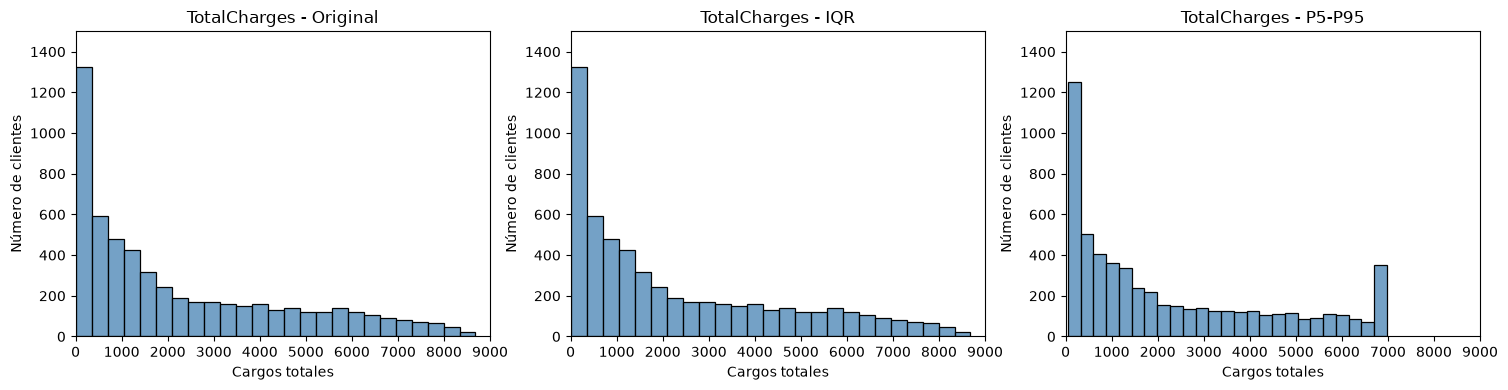

In [51]:
import matplotlib.pyplot as plt
import seaborn as sns

# Comparar histogramas de TotalCharges
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

estrategias = [
    ("Original", X_train),
    ("IQR", X_train_iqr),
    ("P5-P95", X_train_percentiles)
]

for ax, (nombre, datos) in zip(axes, estrategias):
    sns.histplot(
        data=datos,
        x="TotalCharges",
        bins=25,
        color="steelblue",
        edgecolor="black",
        ax=ax
    )

    ax.set_title(f"TotalCharges - {nombre}")
    ax.set_xlabel("Cargos totales")
    ax.set_ylabel("Número de clientes")
    ax.set_xlim(0, 9000)
    ax.set_ylim(0, 1500)

plt.tight_layout()

plt.savefig(
    "../imagenes/comparacion_histogramas_totalcharges.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 5.8. Comparación visual mediante diagramas de caja

Se comparan los diagramas de caja de TotalCharges antes y
después de aplicar winsorización mediante IQR y P5-P95.

El objetivo es observar las diferencias en la mediana,
los cuartiles, la dispersión y los valores extremos.

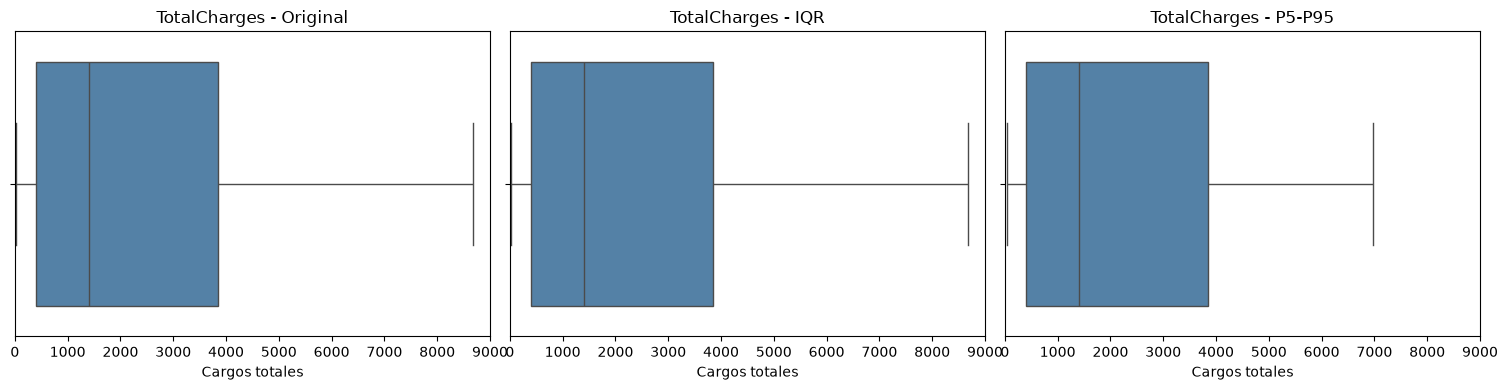

In [52]:
# Comparar diagramas de caja de TotalCharges
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

estrategias = [
    ("Original", X_train),
    ("IQR", X_train_iqr),
    ("P5-P95", X_train_percentiles)
]

for ax, (nombre, datos) in zip(axes, estrategias):
    sns.boxplot(
        data=datos,
        x="TotalCharges",
        color="steelblue",
        ax=ax
    )

    ax.set_title(f"TotalCharges - {nombre}")
    ax.set_xlabel("Cargos totales")
    ax.set_xlim(0, 9000)

plt.tight_layout()

plt.savefig(
    "../imagenes/comparacion_boxplots_totalcharges.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 5.9. Comparación visual de MonthlyCharges

Se compara la distribución de los cargos mensuales antes y
después de aplicar winsorización mediante IQR y P5-P95.


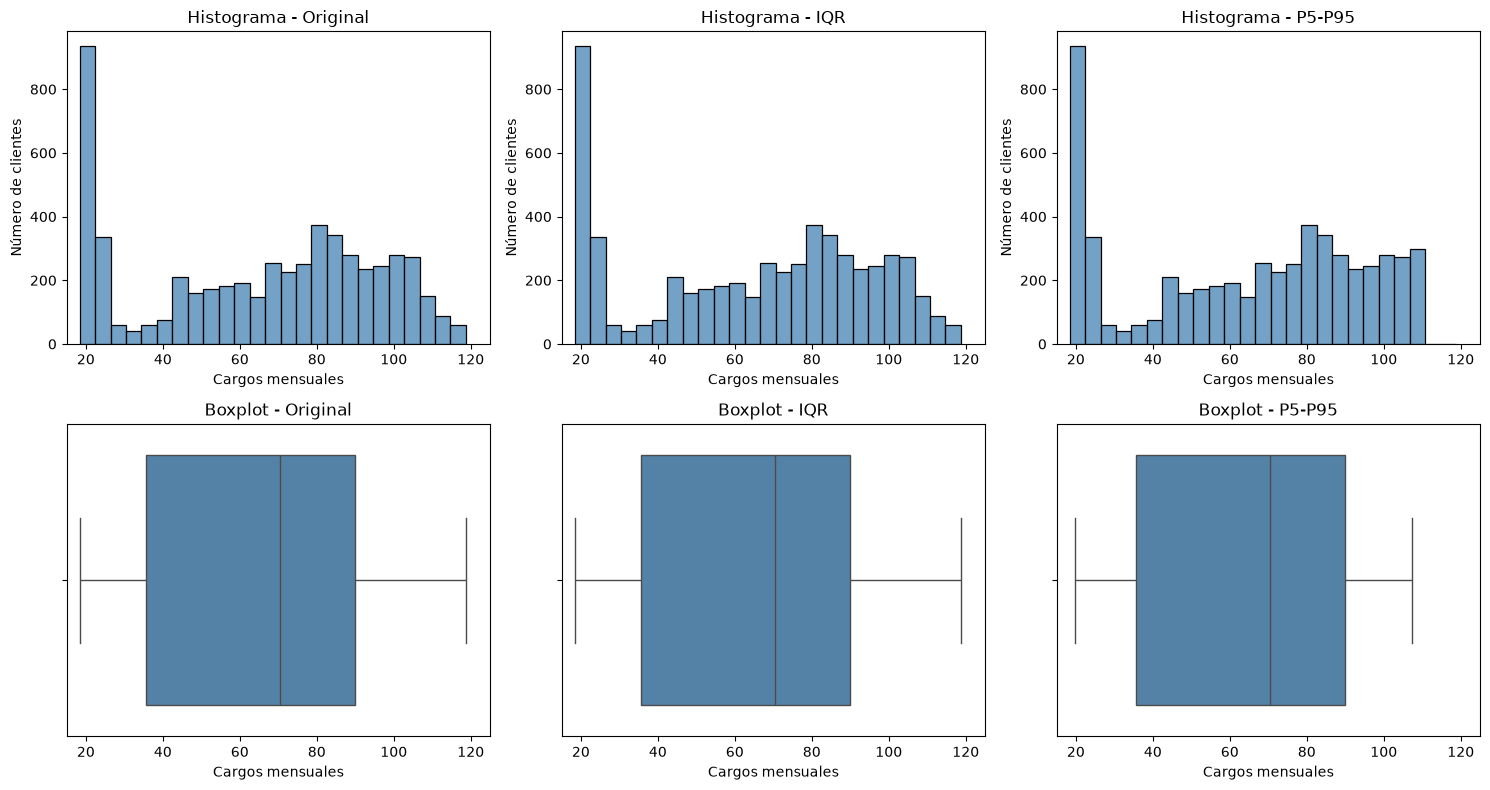

In [53]:
# Comparación de histogramas y boxplots de MonthlyCharges
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

estrategias = [
    ("Original", X_train),
    ("IQR", X_train_iqr),
    ("P5-P95", X_train_percentiles)
]

# Definir intervalos comunes para comparar histogramas
intervalos = np.linspace(
    X_train["MonthlyCharges"].min(),
    X_train["MonthlyCharges"].max(),
    26
)

for i, (nombre, datos) in enumerate(estrategias):

    # Histograma
    sns.histplot(
        data=datos,
        x="MonthlyCharges",
        bins=intervalos,
        color="steelblue",
        edgecolor="black",
        ax=axes[0, i]
    )

    axes[0, i].set_title(f"Histograma - {nombre}")
    axes[0, i].set_xlabel("Cargos mensuales")
    axes[0, i].set_ylabel("Número de clientes")
    axes[0, i].set_xlim(15, 125)

    # Diagrama de caja
    sns.boxplot(
        data=datos,
        x="MonthlyCharges",
        color="steelblue",
        ax=axes[1, i]
    )

    axes[1, i].set_title(f"Boxplot - {nombre}")
    axes[1, i].set_xlabel("Cargos mensuales")
    axes[1, i].set_xlim(15, 125)

plt.tight_layout()

plt.savefig(
    "../imagenes/comparacion_monthlycharges_winsor.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 5.10. Comparación visual de tenure

Se comparan los histogramas y diagramas de caja de la
antigüedad de los clientes antes y después de aplicar
winsorización mediante IQR y percentiles P5-P95.

Se examina especialmente el efecto de modificar los registros
con antigüedad de cero meses.

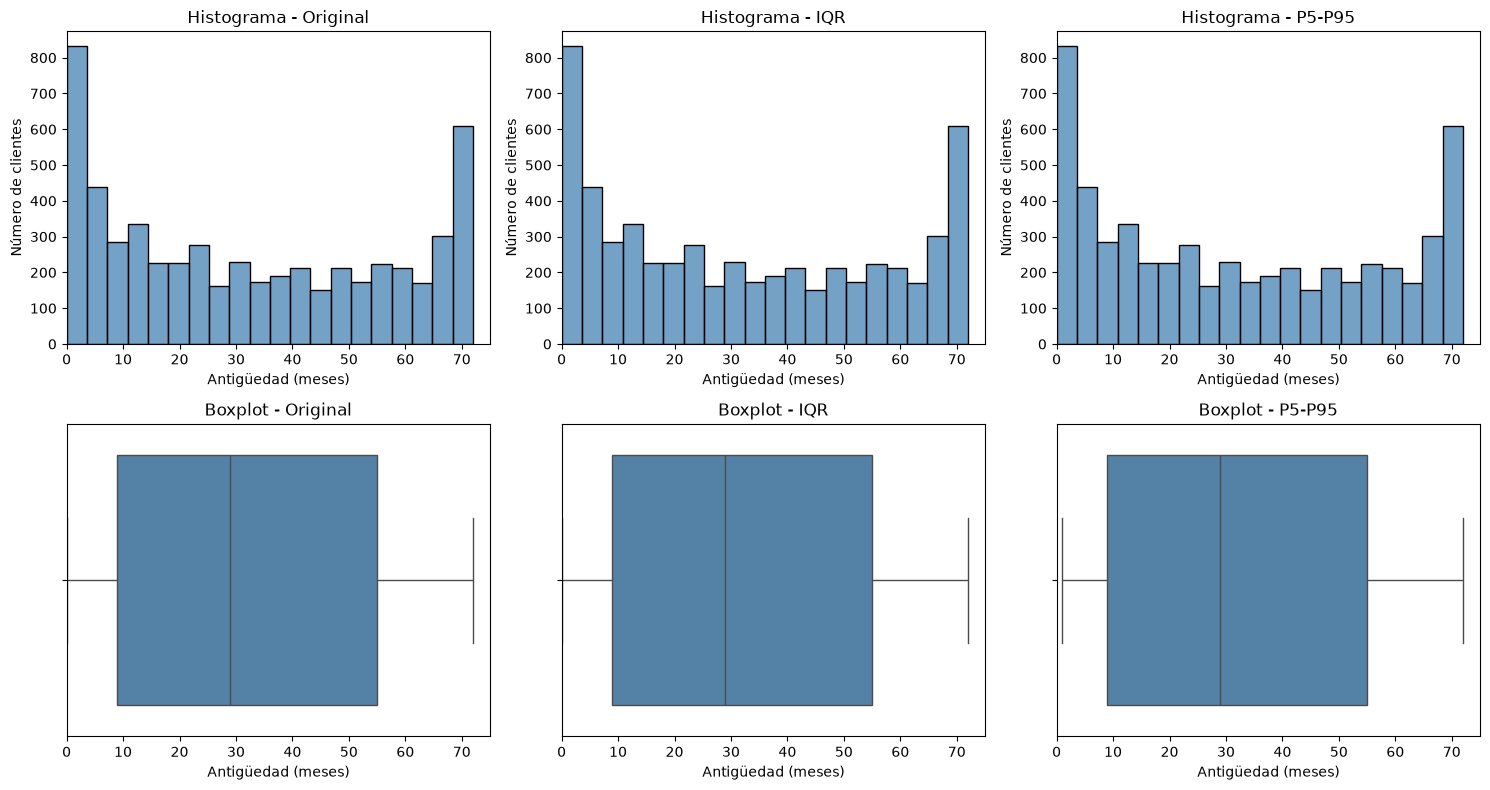

In [54]:
# Comparar histogramas y boxplots de tenure
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

estrategias = [
    ("Original", X_train),
    ("IQR", X_train_iqr),
    ("P5-P95", X_train_percentiles)
]

# Establecer intervalos comunes
intervalos_tenure = np.linspace(0, 72, 21)

for i, (nombre, datos) in enumerate(estrategias):

    # Histograma
    sns.histplot(
        data=datos,
        x="tenure",
        bins=intervalos_tenure,
        color="steelblue",
        edgecolor="black",
        ax=axes[0, i]
    )

    axes[0, i].set_title(f"Histograma - {nombre}")
    axes[0, i].set_xlabel("Antigüedad (meses)")
    axes[0, i].set_ylabel("Número de clientes")
    axes[0, i].set_xlim(0, 75)

    # Boxplot
    sns.boxplot(
        data=datos,
        x="tenure",
        color="steelblue",
        ax=axes[1, i]
    )

    axes[1, i].set_title(f"Boxplot - {nombre}")
    axes[1, i].set_xlabel("Antigüedad (meses)")
    axes[1, i].set_xlim(0, 75)

plt.tight_layout()

plt.savefig(
    "../imagenes/comparacion_tenure_winsor.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 5.11. Evaluación predictiva de la winsorización

Se compararán tres estrategias de tratamiento de valores extremos:

1. Sin winsorización.
2. Winsorización mediante el criterio de 1.5 × IQR.
3. Winsorización mediante percentiles P5 y P95.

Se utilizará regresión logística con validación cruzada
estratificada de cinco particiones.

Los límites de winsorización se calcularán exclusivamente
sobre los datos de entrenamiento de cada partición.

Se mantendrá la imputación por mediana para TotalCharges
y la misma configuración del clasificador.


In [56]:
import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin

class Winsorizador(BaseEstimator, TransformerMixin):

    def __init__(self, metodo="iqr"):
        self.metodo = metodo

    def fit(self, X, y=None):
        datos = np.asarray(X, dtype=float)

        if self.metodo == "iqr":
            q1 = np.nanpercentile(datos, 25, axis=0)
            q3 = np.nanpercentile(datos, 75, axis=0)
            iqr = q3 - q1

            self.limite_inferior_ = q1 - 1.5 * iqr
            self.limite_superior_ = q3 + 1.5 * iqr

        elif self.metodo == "percentiles":
            self.limite_inferior_ = np.nanpercentile(
                datos, 5, axis=0
            )
            self.limite_superior_ = np.nanpercentile(
                datos, 95, axis=0
            )

        else:
            raise ValueError(
                "Método no válido. Utiliza 'iqr' o 'percentiles'."
            )

        return self

    def transform(self, X):
        datos = np.asarray(X, dtype=float)

        return np.clip(
            datos,
            self.limite_inferior_,
            self.limite_superior_
        )

In [57]:
# Pipeline numérico con winsorización IQR
transformador_numerico_iqr = Pipeline(
    steps=[
        ("imputacion", SimpleImputer(strategy="median")),
        ("winsorizacion", Winsorizador(metodo="iqr"))
    ]
)

# Pipeline numérico con winsorización P5-P95
transformador_numerico_percentiles = Pipeline(
    steps=[
        ("imputacion", SimpleImputer(strategy="median")),
        ("winsorizacion", Winsorizador(metodo="percentiles"))
    ]
)

print("Transformador numérico IQR:")
print([nombre for nombre, _ in transformador_numerico_iqr.steps])

print("\nTransformador numérico P5-P95:")
print([nombre for nombre, _ in transformador_numerico_percentiles.steps])

Transformador numérico IQR:
['imputacion', 'winsorizacion']

Transformador numérico P5-P95:
['imputacion', 'winsorizacion']


In [58]:
# Preprocesador con winsorización IQR
preprocesador_winsor_iqr = ColumnTransformer(
    transformers=[
        ("numericas", clone(transformador_numerico_iqr),
         columnas_numericas),

        ("categoricas", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), columnas_categoricas)
    ]
)

# Preprocesador con winsorización P5-P95
preprocesador_winsor_percentiles = ColumnTransformer(
    transformers=[
        ("numericas", clone(transformador_numerico_percentiles),
         columnas_numericas),

        ("categoricas", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), columnas_categoricas)
    ]
)

# Verificar la configuración
print("Preprocesador con winsorización IQR:")
print([
    nombre
    for nombre, _, _ in preprocesador_winsor_iqr.transformers
])

print("\nPreprocesador con winsorización P5-P95:")
print([
    nombre
    for nombre, _, _ in preprocesador_winsor_percentiles.transformers
])

Preprocesador con winsorización IQR:
['numericas', 'categoricas']

Preprocesador con winsorización P5-P95:
['numericas', 'categoricas']


In [59]:
# Pipeline con winsorización mediante IQR
pipeline_winsor_iqr = Pipeline(
    steps=[
        ("preprocesamiento", clone(preprocesador_winsor_iqr)),
        ("escalado", StandardScaler()),
        ("clasificador", clone(clasificador))
    ]
)

# Pipeline con winsorización mediante percentiles P5-P95
pipeline_winsor_percentiles = Pipeline(
    steps=[
        ("preprocesamiento", clone(preprocesador_winsor_percentiles)),
        ("escalado", StandardScaler()),
        ("clasificador", clone(clasificador))
    ]
)

# Comprobar la estructura de los pipelines
print("Pipeline de winsorización IQR:")
print([nombre for nombre, _ in pipeline_winsor_iqr.steps])

print("\nPipeline de winsorización P5-P95:")
print([nombre for nombre, _ in pipeline_winsor_percentiles.steps])

Pipeline de winsorización IQR:
['preprocesamiento', 'escalado', 'clasificador']

Pipeline de winsorización P5-P95:
['preprocesamiento', 'escalado', 'clasificador']


In [60]:
# Evaluar la winsorización mediante IQR
resultados_winsor_iqr = cross_validate(
    estimator=pipeline_winsor_iqr,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=metricas,
    n_jobs=1,
    error_score="raise"
)

# Evaluar la winsorización mediante percentiles P5-P95
resultados_winsor_percentiles = cross_validate(
    estimator=pipeline_winsor_percentiles,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=metricas,
    n_jobs=1,
    error_score="raise"
)

# Mostrar los resultados de ambas estrategias
for nombre, resultados in {
    "IQR": resultados_winsor_iqr,
    "P5-P95": resultados_winsor_percentiles
}.items():

    print(f"\nResultados de winsorización: {nombre}")

    for metrica in metricas:
        valores = resultados[f"test_{metrica}"]

        print(
            f"{metrica}: {valores.mean():.4f} "
            f"(+/- {valores.std():.4f})"
        )


Resultados de winsorización: IQR
accuracy: 0.8025 (+/- 0.0119)
precision: 0.6531 (+/- 0.0255)
recall: 0.5452 (+/- 0.0420)
f1: 0.5936 (+/- 0.0306)
average_precision: 0.6611 (+/- 0.0192)

Resultados de winsorización: P5-P95
accuracy: 0.8030 (+/- 0.0121)
precision: 0.6541 (+/- 0.0254)
recall: 0.5465 (+/- 0.0431)
f1: 0.5948 (+/- 0.0312)
average_precision: 0.6613 (+/- 0.0192)


### 5.12. Comparación del desempeño predictivo

Se comparan los resultados obtenidos mediante validación cruzada
estratificada de cinco particiones para tres estrategias:
sin winsorización, winsorización por IQR y winsorización P5-P95.

Se mantienen constantes la imputación por mediana,
la codificación categórica, la estandarización y el clasificador.


In [61]:
# Reunir los resultados de las tres estrategias
resultados_winsorizacion = {
    "Sin winsorización": resultados_mediana,
    "IQR": resultados_winsor_iqr,
    "P5-P95": resultados_winsor_percentiles
}

# Construir la tabla comparativa
tabla_comparacion_winsor = pd.DataFrame({
    estrategia: {
        metrica: resultados[f"test_{metrica}"].mean()
        for metrica in metricas
    }
    for estrategia, resultados in resultados_winsorizacion.items()
}).T

print("Comparación del desempeño según la winsorización:")
display(tabla_comparacion_winsor.round(4))

Comparación del desempeño según la winsorización:


,accuracy,precision,recall,f1,average_precision
Sin winsorización,0.8025,0.6531,0.5452,0.5936,0.6611
IQR,0.8025,0.6531,0.5452,0.5936,0.6611
P5-P95,0.8030,0.6541,0.5465,0.5948,0.6613


## 6. Tratamiento de desbalance

### 6.1. Diagnóstico del desbalance de clases

Se calcula la cantidad de observaciones por clase, sus porcentajes
y la razón de desbalance (IR) de la variable objetivo Churn.

Se utiliza el conjunto de entrenamiento y el criterio IR > 1.5
establecido en las instrucciones de la práctica.

In [ ]:
# Calcular frecuencias absolutas por clase
frecuencias_clases = y_train.value_counts()

# Calcular porcentajes por clase
porcentajes_clases = y_train.value_counts(normalize=True) * 100

# Calcular la razón de desbalance
IR = frecuencias_clases.max() / frecuencias_clases.min()

print("Cantidad de observaciones por clase:")
print(frecuencias_clases)

print("\nPorcentaje por clase:")
print(porcentajes_clases.round(2))

print("\nRazón de desbalance (IR):")
print(round(IR, 2))

# Evaluar el criterio establecido en la práctica
if IR > 1.5:
    print("\nResultado: El conjunto de entrenamiento está desbalanceado.")
else:
    print("\nResultado: El conjunto de entrenamiento no supera el umbral de desbalance.")

Cantidad de observaciones por clase:
Churn
No     4139
Yes    1495
Name: count, dtype: int64

Porcentaje por clase:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

Razón de desbalance (IR):
2.77

Resultado: El conjunto de entrenamiento está desbalanceado.


### 6.2. Estrategias de tratamiento del desbalance

Se comparan cuatro escenarios:

1. Modelo sin balanceo.
2. Sobremuestreo aleatorio de la clase minoritaria.
3. Submuestreo aleatorio de la clase mayoritaria.
4. Sobremuestreo sintético mediante SMOTENC, una variante
   de SMOTE adaptada a variables categóricas y numéricas.

Se utiliza regresión logística con validación cruzada
estratificada de cinco particiones.

Las técnicas de remuestreo se aplicarán exclusivamente
sobre los datos de entrenamiento de cada partición,
manteniendo reservado el conjunto de prueba.

In [63]:
from imblearn.over_sampling import RandomOverSampler, SMOTENC
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

# Configurar sobremuestreo aleatorio
sobremuestreo = RandomOverSampler(
    random_state=42
)

# Configurar submuestreo aleatorio
submuestreo = RandomUnderSampler(
    random_state=42
)

# Configurar SMOTENC para datos mixtos
smotenc = SMOTENC(
    categorical_features=columnas_categoricas,
    random_state=42,
    k_neighbors=5
)

print("Sobremuestreo:", sobremuestreo)
print("Submuestreo:", submuestreo)
print("SMOTENC:", smotenc)

Sobremuestreo: RandomOverSampler(random_state=42)
Submuestreo: RandomUnderSampler(random_state=42)
SMOTENC: SMOTENC(categorical_features=['gender', 'SeniorCitizen', 'Partner',
                              'Dependents', 'PhoneService', 'MultipleLines',
                              'InternetService', 'OnlineSecurity',
                              'OnlineBackup', 'DeviceProtection', 'TechSupport',
                              'StreamingTV', 'StreamingMovies', 'Contract',
                              'PaperlessBilling', 'PaymentMethod'],
        random_state=42)


In [64]:
from sklearn.base import BaseEstimator, TransformerMixin

class ImputadorTotalCharges(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        self.mediana_ = X["TotalCharges"].median()
        return self

    def transform(self, X):
        datos = X.copy()

        datos["TotalCharges"] = (
            datos["TotalCharges"].fillna(self.mediana_)
        )

        return datos

In [65]:
# Configurar las tres estrategias de balanceo
estrategias_balanceo = {
    "Sobremuestreo": sobremuestreo,
    "Submuestreo": submuestreo,
    "SMOTENC": smotenc
}

# Construir los pipelines de forma compacta
pipelines_balanceo = {}

for nombre, remuestreador in estrategias_balanceo.items():

    pipelines_balanceo[nombre] = ImbPipeline(
        steps=[
            ("imputacion", ImputadorTotalCharges()),
            ("balanceo", clone(remuestreador)),
            ("preprocesamiento", ColumnTransformer(
                transformers=[
                    ("numericas", "passthrough", columnas_numericas),
                    ("categoricas", OneHotEncoder(
                        handle_unknown="ignore",
                        sparse_output=False
                    ), columnas_categoricas)
                ]
            )),
            ("escalado", StandardScaler()),
            ("clasificador", clone(clasificador))
        ]
    )

# Verificar la estructura
for nombre, pipeline in pipelines_balanceo.items():
    print(f"\nPipeline: {nombre}")
    print([paso for paso, _ in pipeline.steps])


Pipeline: Sobremuestreo
['imputacion', 'balanceo', 'preprocesamiento', 'escalado', 'clasificador']

Pipeline: Submuestreo
['imputacion', 'balanceo', 'preprocesamiento', 'escalado', 'clasificador']

Pipeline: SMOTENC
['imputacion', 'balanceo', 'preprocesamiento', 'escalado', 'clasificador']


### 6.3. Evaluación comparativa de estrategias de balanceo

Se evalúan las técnicas de sobremuestreo aleatorio, submuestreo
aleatorio y SMOTENC mediante validación cruzada estratificada
de cinco particiones.

El remuestreo se aplica exclusivamente a los datos de
entrenamiento de cada partición para evitar fugas de información.

Se utiliza el mismo clasificador de regresión logística y
se comparan accuracy, precision, recall, F1-score y
Average Precision, considerando Churn = Yes como clase positiva.

In [66]:
# Evaluar las tres estrategias de balanceo
resultados_balanceo = {}

for nombre, pipeline in pipelines_balanceo.items():

    print(f"Evaluando estrategia: {nombre}")

    resultados = cross_validate(
        estimator=pipeline,
        X=X_train,
        y=y_train,
        cv=cv,
        scoring=metricas,
        n_jobs=1,
        error_score="raise"
    )

    resultados_balanceo[nombre] = resultados

    print(f"Evaluación de {nombre} completada.\n")

Evaluando estrategia: Sobremuestreo
Evaluación de Sobremuestreo completada.

Evaluando estrategia: Submuestreo
Evaluación de Submuestreo completada.

Evaluando estrategia: SMOTENC
Evaluación de SMOTENC completada.



### 6.4. Comparación del desempeño predictivo

Se comparan los resultados del modelo sin balanceo con
las estrategias de sobremuestreo aleatorio, submuestreo
aleatorio y SMOTENC.

Se utilizan los promedios de accuracy, precision, recall,
F1-score y Average Precision obtenidos mediante validación
cruzada estratificada de cinco particiones.

In [67]:
# Incorporar el modelo original sin balanceo
resultados_comparacion_balanceo = {
    "Sin balanceo": resultados_mediana,
    **resultados_balanceo
}

# Construir tabla comparativa
tabla_balanceo = pd.DataFrame({
    estrategia: {
        metrica: resultados[f"test_{metrica}"].mean()
        for metrica in metricas
    }
    for estrategia, resultados in resultados_comparacion_balanceo.items()
}).T

print("Comparación de estrategias de balanceo:")
display(tabla_balanceo.round(4))

Comparación de estrategias de balanceo:


,accuracy,precision,recall,f1,average_precision
Sin balanceo,0.8025,0.6531,0.5452,0.5936,0.6611
Sobremuestreo,0.7467,0.5145,0.8013,0.6265,0.6584
Submuestreo,0.7460,0.5140,0.8027,0.6265,0.6613
SMOTENC,0.7668,0.5449,0.7371,0.6264,0.6396


### 6.5. Interpretación de las estrategias de balanceo

Las técnicas de balanceo incrementaron el recall del clasificador
respecto al modelo original sin balanceo.

El sobremuestreo y el submuestreo alcanzaron valores de recall
cercanos al 80%, frente al 54.52% del modelo de referencia.

Sin embargo, estas mejoras estuvieron acompañadas de una
reducción en accuracy y precision, lo que implica una mayor
proporción de falsas alarmas entre las predicciones positivas.

SMOTENC presentó un comportamiento intermedio, con recall
de 73.71% y precision de 54.49%.

Los resultados muestran que el tratamiento del desbalance
implica compromisos entre distintas métricas de evaluación.
No se considera suficiente seleccionar una estrategia
únicamente por su accuracy.

Los métodos de remuestreo se aplicaron exclusivamente dentro
de las particiones de entrenamiento de la validación cruzada.

### 6.6. Estabilidad de los resultados

Se analiza la desviación estándar de recall, F1-score
y Average Precision entre las cinco particiones de
validación cruzada.

El objetivo es comparar la variabilidad del desempeño
de las estrategias de balanceo.

In [68]:
# Seleccionar las métricas para analizar su estabilidad
metricas_estabilidad = ["recall", "f1", "average_precision"]

# Calcular desviaciones estándar por estrategia
tabla_estabilidad = pd.DataFrame({
    estrategia: {
        metrica: resultados[f"test_{metrica}"].std()
        for metrica in metricas_estabilidad
    }
    for estrategia, resultados in resultados_comparacion_balanceo.items()
}).T

print("Desviación estándar entre particiones:")
display(tabla_estabilidad.round(4))

Desviación estándar entre particiones:


,recall,f1,average_precision
Sin balanceo,0.0420,0.0306,0.0192
Sobremuestreo,0.0406,0.0213,0.0215
Submuestreo,0.0267,0.0183,0.0189
SMOTENC,0.0321,0.0213,0.0237


## 7. Evaluación final del clasificador

### 7.1. Configuración del modelo seleccionado

Se selecciona provisionalmente el submuestreo aleatorio
como estrategia de balanceo, considerando su recall,
F1-score y estabilidad durante la validación cruzada.

El modelo utiliza imputación por mediana, codificación
categórica, estandarización y regresión logística.

Se entrenará utilizando todo el conjunto de entrenamiento.
El conjunto de prueba se utilizará únicamente para
la evaluación final.

In [69]:
# Crear una copia independiente del pipeline seleccionado
modelo_final = clone(pipelines_balanceo["Submuestreo"])

# Entrenar el modelo con todo el conjunto de entrenamiento
modelo_final.fit(X_train, y_train)

# Confirmar que el entrenamiento terminó correctamente
print("Modelo final entrenado correctamente.")

print("\nEtapas del modelo:")
print([nombre for nombre, _ in modelo_final.steps])

print("\nClases reconocidas por el clasificador:")
print(modelo_final.named_steps["clasificador"].classes_)

Modelo final entrenado correctamente.

Etapas del modelo:
['imputacion', 'balanceo', 'preprocesamiento', 'escalado', 'clasificador']

Clases reconocidas por el clasificador:
['No' 'Yes']


### 7.2. Predicciones sobre el conjunto de prueba

Se utiliza el modelo seleccionado para generar predicciones
sobre los 1,409 registros reservados para prueba.

Se obtienen las clases predichas y las probabilidades
estimadas de cancelación, con el propósito de evaluar
el desempeño final del clasificador.

In [70]:
# Generar predicciones sobre el conjunto de prueba
y_pred = modelo_final.predict(X_test)

# Obtener probabilidades de la clase positiva (Yes)
indice_yes = list(
    modelo_final.named_steps["clasificador"].classes_
).index("Yes")

y_prob = modelo_final.predict_proba(X_test)[:, indice_yes]

print("Total de predicciones:", len(y_pred))
print("Total de probabilidades:", len(y_prob))

print("\nDistribución de las clases predichas:")
print(pd.Series(y_pred).value_counts())

print("\nPrimeras cinco probabilidades de cancelación:")
print(np.round(y_prob[:5], 4))

Total de predicciones: 1409
Total de probabilidades: 1409

Distribución de las clases predichas:
No     833
Yes    576
Name: count, dtype: int64

Primeras cinco probabilidades de cancelación:
[0.142  0.8771 0.1552 0.6695 0.0581]


### 7.3. Evaluación de métricas finales

Se evalúa el desempeño del clasificador sobre el conjunto
de prueba mediante accuracy, precision, recall, F1-score
y Average Precision.

Se considera Churn = Yes como la clase positiva.

Los resultados permiten analizar la capacidad del modelo
para identificar clientes que cancelaron su servicio.

In [71]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

# Calcular las métricas finales del clasificador
metricas_finales = {
    "Accuracy": accuracy_score(y_test, y_pred),

    "Precision": precision_score(
        y_test, y_pred, pos_label="Yes"
    ),

    "Recall": recall_score(
        y_test, y_pred, pos_label="Yes"
    ),

    "F1-score": f1_score(
        y_test, y_pred, pos_label="Yes"
    ),

    "Average Precision": average_precision_score(
        y_test, y_prob, pos_label="Yes"
    )
}

print("Resultados finales del clasificador:")

for nombre, valor in metricas_finales.items():
    print(f"{nombre}: {valor:.4f} ({valor * 100:.2f}%)")

Resultados finales del clasificador:
Accuracy: 0.7431 (74.31%)
Precision: 0.5104 (51.04%)
Recall: 0.7861 (78.61%)
F1-score: 0.6189 (61.89%)
Average Precision: 0.6305 (63.05%)


### 7.4. Matriz de confusión del clasificador

Se construye la matriz de confusión para identificar
verdaderos negativos, falsos positivos, falsos negativos
y verdaderos positivos.

Se considera Churn = Yes como la clase positiva.

Matriz de confusión:
[[753 282]
 [ 80 294]]


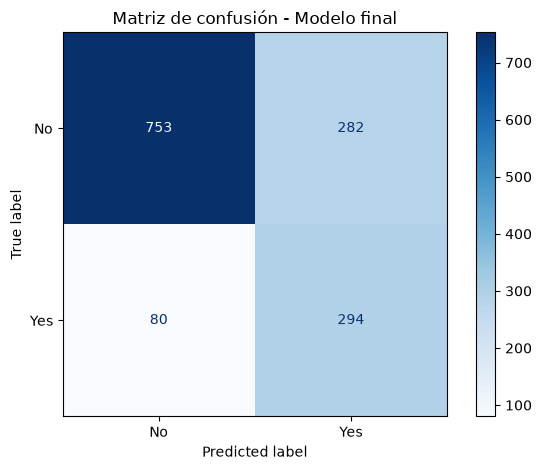

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Definir el orden de las clases
clases = ["No", "Yes"]

# Calcular la matriz de confusión
matriz_confusion = confusion_matrix(
    y_test,
    y_pred,
    labels=clases
)

# Mostrar los valores numéricos
print("Matriz de confusión:")
print(matriz_confusion)

# Generar la visualización
disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_confusion,
    display_labels=clases
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Matriz de confusión - Modelo final")
plt.tight_layout()

plt.savefig(
    "../imagenes/matriz_confusion_modelo_final.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 7.5. Curva Precision-Recall

Se construye la curva Precision-Recall utilizando las
probabilidades estimadas de cancelación sobre el conjunto
de prueba.

Se analiza el comportamiento de precision y recall ante
diferentes umbrales de clasificación.

Se utiliza Average Precision (AP) para resumir el
desempeño de la curva.

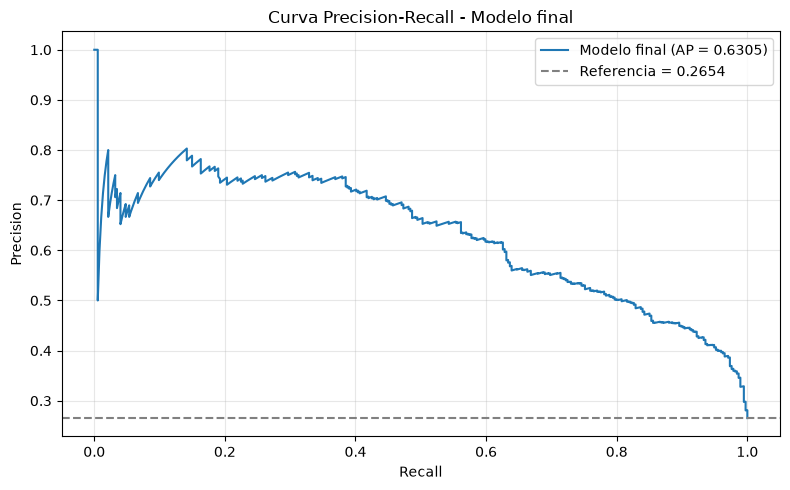

Average Precision final: 0.6305


In [73]:
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

# Convertir la clase positiva a representación binaria
y_test_binario = (y_test == "Yes").astype(int)

# Calcular precision y recall para diferentes umbrales
precision_curva, recall_curva, umbrales = precision_recall_curve(
    y_test_binario,
    y_prob
)

# Calcular Average Precision
ap_final = average_precision_score(
    y_test_binario,
    y_prob
)

# Generar gráfica
plt.figure(figsize=(8, 5))

plt.plot(
    recall_curva,
    precision_curva,
    label=f"Modelo final (AP = {ap_final:.4f})"
)

# Línea de referencia según la proporción de positivos
proporcion_positivos = y_test_binario.mean()

plt.axhline(
    y=proporcion_positivos,
    linestyle="--",
    color="gray",
    label=f"Referencia = {proporcion_positivos:.4f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Curva Precision-Recall - Modelo final")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../imagenes/curva_precision_recall_final.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Average Precision final:", round(ap_final, 4))

### 7.6. Interpretación final del clasificador

El modelo de regresión logística con submuestreo aleatorio
obtuvo un accuracy de 74.31%, precision de 51.04%,
recall de 78.61%, F1-score de 61.89% y
Average Precision de 63.05%.

La matriz de confusión mostró 294 verdaderos positivos,
753 verdaderos negativos, 282 falsos positivos y
80 falsos negativos.

Los resultados indican que el clasificador identifica
la mayoría de las cancelaciones reales, aunque genera
una cantidad considerable de falsas alarmas.

La curva Precision-Recall mostró un desempeño superior
a la referencia basada en la proporción de clientes que
cancelaron, aunque la precision disminuye conforme
aumenta el recall.

El modelo presenta un compromiso entre identificar más
cancelaciones y reducir las predicciones positivas incorrectas.

Estos resultados corresponden al conjunto de prueba reservado,
utilizado después de seleccionar las estrategias mediante
validación cruzada.